# Homework 2: Measure Your Camera's Spatial Resolution
## Name: Jon Knapp
### Date: November 12, 2026
### Class: EE 513 Intro to Image Processing

## AI Disclosure:

I used Claude (Anthropic) to write the notebook’s code (calibration, the MTF prediction, the slanted-edge routine and the Part 4 pipeline), to diagnose problems in my captures (a non-flat checkerboard, blurry corners, a distortion model limited by where my corners reached, and close-range defocus and off-centre framing in the slanted-edge shots), to explain concepts, and to draft the written answers for items 4, 6, 8, 14 and 16, which I reviewed and edited. I verified the output by testing the slanted-edge code on a synthetic Gaussian edge with a known analytic MTF50 (items 9–11, −0.12 % error, and within 0.7 % across other blur widths, edge angles, orientations and added noise), by checking the calibration with a per-photo plane-fit test and a comparison of four- and five-coefficient distortion models, by cross-checking the pixel pitch two independent ways and against Apple’s published 2.44 µm, and by retaking the captures until repeated photos agreed.

AI was used in the following ways:
* Code generation
* Checking my work and my logic
* Checking and assistance with reflections

## Setup

Order of work required by the assignment: complete Parts 1 and 2 **before** taking the slanted-edge captures, and do not revise the predicted values afterward. The Part 2 results are written to `hw2_predictions.json` the first time item 8 runs and are never overwritten after that, so settle the calibration captures and `PITCH_CHOICE` (item 4) first.

Folders:
* `Homework 1 Image Captures/`: Exercise 1 checkerboard captures (used for Part 1 until new ones exist)
* `Homework 2 Image Captures/Checkerboard/`: re-shot checkerboard captures, used automatically once it holds 15 or more DNGs
* `Homework 2 Image Captures/Slanted Edge/`: the Part 4 captures

In [1]:
# If rawpy or tifffile isn't installed:  %pip install rawpy tifffile
import json
from datetime import datetime
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rawpy
import tifffile
from matplotlib.patches import Rectangle
from scipy.optimize import brentq
from scipy.special import erf

def dng_files(folder):
    folder = Path(folder)
    if not folder.is_dir():
        return []
    return sorted(f for f in folder.iterdir() if f.suffix.lower() == ".dng")


# --- Part 1: checkerboard captures --------------------------------------------
# New captures (target taped flat to a rigid board) go in NEW_CAL_DIR. Once it holds at least
# 15 DNGs it is used automatically; until then the Exercise 1 captures are used.
NEW_CAL_DIR = Path("Homework 2 Image Captures") / "Checkerboard"
if len(dng_files(NEW_CAL_DIR)) >= 15:
    CAL_DIR = NEW_CAL_DIR
    CAL_FILES = dng_files(NEW_CAL_DIR)
else:
    CAL_DIR = Path("Homework 1 Image Captures")
    CAL_FILES = [CAL_DIR / f"IMG_{i:04d}.DNG" for i in range(360, 392)]
print(f"Calibration captures: {len(CAL_FILES)} files in '{CAL_DIR}'")
PATTERN = (9, 6)            # inner corners per row, rows
SQUARE_MM = 20.0            # MEASURED square size from Exercise 1, item 9 (not the nominal value)
EXCLUDE = []                # file names to leave out of the calibration, e.g. ["IMG_0371.DNG"]
STRAIGHT_EDGE_FILE = None   # item 2: None = pick the calibration frame with a board edge nearest the
                            # frame boundary; or a Path to a dedicated photo of a long straight edge
CORNER_CACHE = Path("hw2_checkerboard_corners.npz")   # detection takes ~1 min; cached after the first run

# --- Part 2 constants ---------------------------------------------------------
WAVELENGTH_UM = 0.55        # green light
FILM_DIAG_MM = 43.3         # diagonal of 36 x 24 mm film
PREDICTION_FILE = Path("hw2_predictions.json")

# --- Part 4: slanted-edge captures --------------------------------------------
EDGE_DIR = Path("Homework 2 Image Captures") / "Slanted Edge"

Calibration captures: 25 files in 'Homework 2 Image Captures\Checkerboard'


In [2]:
# --- lens_id helper, as given on the Project 1 page ---------------------------
def lens_id(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]
        return (exif.get("LensModel", "unknown"),
                round(fl[0] / fl[1], 3),
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))


def _lookup(page, name):
    """Find a tag in the EXIF sub-IFD, falling back to IFD0."""
    exif = page.tags["ExifTag"].value if "ExifTag" in page.tags else {}
    if name in exif:
        return exif[name]
    if name in page.tags:
        return page.tags[name].value
    return None


def _num(v):
    """EXIF rationals arrive as (numerator, denominator) tuples."""
    if isinstance(v, (tuple, list)):
        return v[0] / v[1] if len(v) == 2 else float(v[0])
    return None if v is None else float(v)


def camera_exif(path):
    """The EXIF values this assignment needs, as plain numbers."""
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        iso = _lookup(p, "ISOSpeedRatings") or _lookup(p, "PhotographicSensitivity")
        return {
            "file": Path(path).name,
            "lens": _lookup(p, "LensModel"),
            "f_mm": _num(_lookup(p, "FocalLength")),
            "f35_mm": _num(_lookup(p, "FocalLengthIn35mmFilm")),
            "N": _num(_lookup(p, "FNumber")),
            "exposure_s": _num(_lookup(p, "ExposureTime")),
            "ISO": int(iso[0] if isinstance(iso, (tuple, list)) else iso) if iso else None,
        }


def srgb_encode(x):
    """Piecewise sRGB transfer function, linear [0, 1] -> encoded [0, 1]."""
    x = np.clip(x, 0, 1)
    return np.where(x <= 0.0031308, 12.92 * x, 1.055 * np.power(x, 1 / 2.4) - 0.055)


def load_rgb(path):
    """Demosaiced 8-bit RGB in sensor orientation (user_flip=0), so every frame shares one pixel grid."""
    with rawpy.imread(str(path)) as raw:
        return raw.postprocess(use_camera_wb=True, user_flip=0)

## Part 1: Camera Geometry
### Problem 1: Calibrate your camera with cv2.calibrateCamera from at least 15 successful checkerboard detections, using the square size you measured in Exercise 1 rather than the nominal 20.0 mm. Report the focal lengths in pixels and in millimeters, the principal point, the four distortion coefficients, and the RMS reprojection error.
_Deliverable: Labeled list of the calibration parameters with units._

In [3]:
SCALE = 4     # detect on a 1/4-size copy, then refine at full resolution
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)


REFINE = "subpix-window-0.3-square"   # recorded in the cache; changing the refinement re-detects


def detect_corners(path):
    gray = cv2.cvtColor(load_rgb(path), cv2.COLOR_RGB2GRAY)
    small = cv2.resize(gray, None, fx=1 / SCALE, fy=1 / SCALE, interpolation=cv2.INTER_AREA)
    found, c = cv2.findChessboardCorners(small, PATTERN)
    if not found:
        return None, gray.shape[::-1]
    c = (c * SCALE + (SCALE - 1) / 2).astype(np.float32)   # back to full-resolution coordinates
    # The refinement window has to span the blur around each corner. A fixed 11 px window is fine
    # for sharp, small squares but fails on close, defocused boards whose edges are 5-10 px wide,
    # so scale it to the square size (0.3 of a square: large, but never reaching the next corner).
    square_px = np.median(np.hypot(*np.diff(c.reshape(PATTERN[1], PATTERN[0], 2), axis=1).reshape(-1, 2).T))
    half = int(np.clip(0.3 * square_px, 5, 40))
    return cv2.cornerSubPix(gray, c, (half, half), (-1, -1), criteria), gray.shape[::-1]


names = [p.name for p in CAL_FILES]
cache_ok = False
if CORNER_CACHE.exists():
    z = np.load(CORNER_CACHE, allow_pickle=True)
    cache_ok = (list(z["names"]) == names and tuple(z["pattern"]) == PATTERN
                and "refine" in z.files and str(z["refine"]) == REFINE)
if cache_ok:
    all_corners = z["corners"].item()
    image_size = tuple(int(v) for v in z["image_size"])
    print(f"Loaded corners from {CORNER_CACHE} (delete it to re-detect)")
else:
    all_corners = {}
    for p in CAL_FILES:
        c, image_size = detect_corners(p)
        if c is not None:
            all_corners[p.name] = c
    np.savez(CORNER_CACHE, names=np.array(names), pattern=np.array(PATTERN),
             corners=np.array(all_corners, dtype=object), image_size=np.array(image_size),
             refine=np.array(REFINE))

failed = [n for n in names if n not in all_corners]
print(f"findChessboardCorners succeeded on {len(all_corners)} of {len(names)} captures"
      + (f"; failed: {failed}" if failed else ""))
print(f"Image size (width, height): {image_size}")

Loaded corners from hw2_checkerboard_corners.npz (delete it to re-detect)
findChessboardCorners succeeded on 25 of 25 captures
Image size (width, height): (4032, 3024)


In [4]:
used_names = [n for n in names if n in all_corners and n not in EXCLUDE]
assert len(used_names) >= 15, f"Only {len(used_names)} detections; the assignment needs at least 15."

objp = np.zeros((PATTERN[0] * PATTERN[1], 3), np.float32)
objp[:, :2] = np.mgrid[0:PATTERN[0], 0:PATTERN[1]].T.reshape(-1, 2) * SQUARE_MM
img_points = [all_corners[n] for n in used_names]
obj_points = [objp] * len(img_points)

# USE_K3 = False holds k3 at zero, giving exactly the four coefficients the assignment asks for
# (k1, k2, p1, p2). True adds the sixth-order radial term k3.
USE_K3 = True
DIST_FLAGS = 0 if USE_K3 else cv2.CALIB_FIX_K3
(rms, K, dist, rvecs, tvecs,
 sd_intr, sd_extr, per_view) = cv2.calibrateCameraExtended(
    obj_points, img_points, image_size, None, None, flags=DIST_FLAGS)
dist = dist.ravel()
sd_intr = sd_intr.ravel()
per_view = per_view.ravel()

fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
k1, k2, p1, p2, k3 = dist[:5]

# The camera's EXIF (same for every calibration frame; item 4 checks this)
cal_exif = pd.DataFrame([camera_exif(CAL_DIR / n) for n in used_names])
F_EXIF_MM = cal_exif.f_mm.iloc[0]
F35_MM = cal_exif.f35_mm.iloc[0]
N_EXIF = cal_exif.N.iloc[0]

# Focal length in mm needs a pixel pitch. Use the route that does not depend on this
# calibration (EXIF crop factor, item 4), so the mm values are an independent check on the EXIF focal length.
crop = F35_MM / F_EXIF_MM
pitch_exif_um = 1000 * (FILM_DIAG_MM / crop) / np.hypot(*image_size)
# The other distortion model, for comparison: if adding k3 removes most of the error, the
# limit is the four-coefficient model at the frame edges rather than the target.
rms_alt = cv2.calibrateCamera(obj_points, img_points, image_size, None, None,
                              flags=cv2.CALIB_FIX_K3 if USE_K3 else 0)[0]

calib_rows = [
    ("focal length f_x", fx, sd_intr[0], "px"),
    ("focal length f_y", fy, sd_intr[1], "px"),
    ("focal length f_x", fx * pitch_exif_um / 1000, sd_intr[0] * pitch_exif_um / 1000, "mm"),
    ("focal length f_y", fy * pitch_exif_um / 1000, sd_intr[1] * pitch_exif_um / 1000, "mm"),
    ("principal point c_x", cx, sd_intr[2], "px"),
    ("principal point c_y", cy, sd_intr[3], "px"),
    ("radial k1", k1, sd_intr[4], "dimensionless"),
    ("radial k2", k2, sd_intr[5], "dimensionless"),
    ("tangential p1", p1, sd_intr[6], "dimensionless"),
    ("tangential p2", p2, sd_intr[7], "dimensionless"),
    ("RMS reprojection error without k3", rms_alt, np.nan, "px"),
    ("RMS reprojection error with k3", rms, np.nan, "px")
]
if USE_K3:
    calib_rows.insert(10, ("radial k3", k3, sd_intr[8], "dimensionless"))
calib_table = pd.DataFrame(calib_rows, columns=["parameter", "value", "±1σ (from the fit)", "units"])

print(f"{len(used_names)} views, square size {SQUARE_MM} mm, image {image_size[0]} x {image_size[1]} px")
print(f"mm values use pitch {pitch_exif_um:.3f} µm from the EXIF crop factor (item 4, route 2); "
      f"EXIF focal length is {F_EXIF_MM:.3f} mm")
# The other distortion model, for comparison: if adding k3 removes most of the error, the
# limit is the four-coefficient model at the frame edges rather than the target.
rms_alt = cv2.calibrateCamera(obj_points, img_points, image_size, None, None,
                              flags=cv2.CALIB_FIX_K3 if USE_K3 else 0)[0]
print(f"RMS with k1 k2 p1 p2: {rms_alt if USE_K3 else rms:.3f} px; with k3 added: {rms if USE_K3 else rms_alt:.3f} px "
      f"(this table: {'with' if USE_K3 else 'without'} k3)")
if rms > 1.0:
    print(f"! RMS {rms:.2f} px is above ~1 px: suspect the target (flatness) before the code.")
calib_table.style.hide(axis="index").format({"value": "{:.5g}", "±1σ (from the fit)": "{:.2g}"})

25 views, square size 20.0 mm, image 4032 x 3024 px
mm values use pitch 2.422 µm from the EXIF crop factor (item 4, route 2); EXIF focal length is 6.765 mm
RMS with k1 k2 p1 p2: 1.440 px; with k3 added: 0.863 px (this table: with k3)


parameter,value,±1σ (from the fit),units
focal length f_x,2898.1,1.3,px
focal length f_y,2905.6,1.3,px
focal length f_x,7.0181,0.003,mm
focal length f_y,7.0364,0.0031,mm
principal point c_x,2026.1,1.3,px
principal point c_y,1510,1.4,px
radial k1,0.23202,0.0022,dimensionless
radial k2,-0.94611,0.011,dimensionless
tangential p1,0.0010221,0.00016,dimensionless
tangential p2,-0.00074888,0.00015,dimensionless


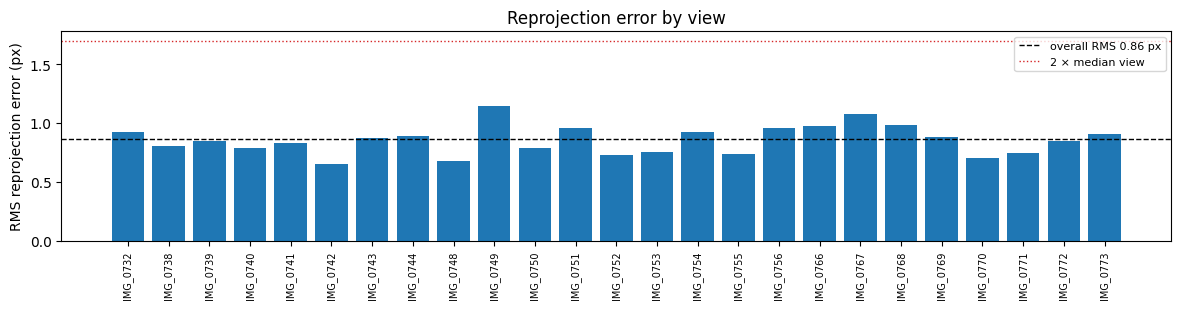

Worst five views (px): IMG_0749.DNG 1.14, IMG_0767.DNG 1.08, IMG_0768.DNG 0.98, IMG_0766.DNG 0.97, IMG_0751.DNG 0.96


In [5]:
# Per-view reprojection error: a few bad views (motion blur, a curled sheet) can dominate the RMS.
fig, ax = plt.subplots(figsize=(12, 3.2))
med = np.median(per_view)
colors = ["tab:red" if e > 2 * med else "tab:blue" for e in per_view]
ax.bar(range(len(per_view)), per_view, color=colors)
ax.axhline(rms, color="k", ls="--", lw=1, label=f"overall RMS {rms:.2f} px")
ax.axhline(2 * med, color="tab:red", ls=":", lw=1, label="2 × median view")
ax.set_xticks(range(len(per_view)), [n.replace(".DNG", "") for n in used_names], rotation=90, fontsize=7)
ax.set_ylabel("RMS reprojection error (px)")
ax.set_title("Reprojection error by view")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

worst = pd.Series(per_view, index=used_names).sort_values(ascending=False)
print("Worst five views (px):", ", ".join(f"{n} {e:.2f}" for n, e in worst.head(5).items()))

In [6]:
# Target or code? A flat target maps to the image by a homography, and over a board that fills a
# fraction of the frame lens distortion is a small correction to that. So the residual of a plain
# homography fit, view by view, is a direct test of flatness: well-located corners on a flat sheet
# fit to a few tenths of a pixel. Residuals of 1-3 px that point in random directions mean the sheet
# itself is not a plane (cockled or curled paper), which no camera model can absorb.
def homography_rms(corners):
    c = corners.reshape(-1, 2)
    H, _ = cv2.findHomography(objp[:, :2], c)
    proj = cv2.perspectiveTransform(objp[:, :2].reshape(-1, 1, 2), H).reshape(-1, 2)
    return np.sqrt(((c - proj) ** 2).sum(axis=1).mean())

flat = pd.DataFrame({
    "file": used_names,
    "board_width_px": [np.ptp(all_corners[n].reshape(-1, 2)[:, 0]) for n in used_names],
    "homography_rms_px": [homography_rms(all_corners[n]) for n in used_names],
    "calibration_rms_px": per_view,
})
print(f"Homography-only residual: median {flat.homography_rms_px.median():.2f} px, "
      f"max {flat.homography_rms_px.max():.2f} px")
flat.sort_values("homography_rms_px", ascending=False).head(8).round(2).style.hide(axis="index")

Homography-only residual: median 2.22 px, max 2.85 px


file,board_width_px,homography_rms_px,calibration_rms_px
IMG_0769.DNG,1705.000000,2.850000,0.880000
IMG_0766.DNG,1588.459961,2.840000,0.970000
IMG_0768.DNG,1527.329956,2.710000,0.980000
IMG_0772.DNG,1723.739990,2.700000,0.850000
IMG_0771.DNG,1440.670044,2.640000,0.740000
IMG_0738.DNG,1958.369995,2.550000,0.810000
IMG_0751.DNG,1844.020020,2.540000,0.960000
IMG_0770.DNG,1322.010010,2.500000,0.700000


<div style="background-color:#ffe6e6; border:3px solid #cc0000; border-radius:6px; padding:14px; text-align:center;">
  <span style="color:#cc0000; font-size:1.5em; font-weight:bold;">
    ⚠️ PROBLEM 1 ASKED FOR FOUR DISTORTION COEFFICIENTS. THESE VALUES ARE DERIVED USING FIVE DISTORTION COEFFICIENTS. ⚠️
  </span>
</div>

Using only four distortion coefficients (k1, k2, p1, and p2), the RMS value overall was 1.4397 px. Adding in the fifth distortion coefficient brought down the RMS value overall to 0.86295 px, which meets the given standard of being below 1.00 px. This is evidence that the model with the four distortion coefficients (k1, k2, p1, and p2) couldn't adequately handle the purposefully added corner and edge images (IMG_0766 - IMG_0773). These images were added for Problem 2.

**Calibration with four and with five distortion coefficients** (same 25 views, square size 20.0 mm; mm values use the 2.422 µm pitch from item 4, route 2; ± is 1σ from the fit):

| Parameter | Four coefficients (k1, k2, p1, p2) | Five coefficients (k1, k2, p1, p2, k3) | Units |
|---|---|---|---|
| focal length f_x | 2910.2 ± 2.1 | 2898.1 ± 1.3 | px |
| focal length f_y | 2919.0 ± 2.1 | 2905.6 ± 1.3 | px |
| focal length f_x | 7.0475 ± 0.0050 | 7.0181 ± 0.0030 | mm |
| focal length f_y | 7.0689 ± 0.0052 | 7.0364 ± 0.0031 | mm |
| principal point c_x | 2030.7 ± 2.1 | 2026.1 ± 1.3 | px |
| principal point c_y | 1515.4 ± 2.2 | 1510.0 ± 1.4 | px |
| radial k1 | 0.11368 ± 0.0019 | 0.23202 ± 0.0022 | dimensionless |
| radial k2 | −0.2679 ± 0.0038 | −0.94611 ± 0.011 | dimensionless |
| tangential p1 | 0.0017406 ± 0.00025 | 0.0010221 ± 0.00016 | dimensionless |
| tangential p2 | −0.000023 ± 0.00023 | −0.00074888 ± 0.00015 | dimensionless |
| radial k3 | 0 (held fixed) | 1.0703 ± 0.017 | dimensionless |
| **RMS reprojection error** | **1.4397** | **0.86295** | px |

### Problem 2: Undistort an image that contains a long straight edge near the boundary of the frame, where distortion is largest.
_Deliverable: The original and undistorted images, side by side._

Row 0 of IMG_0748.DNG lies 48% of the half-diagonal from the principal point


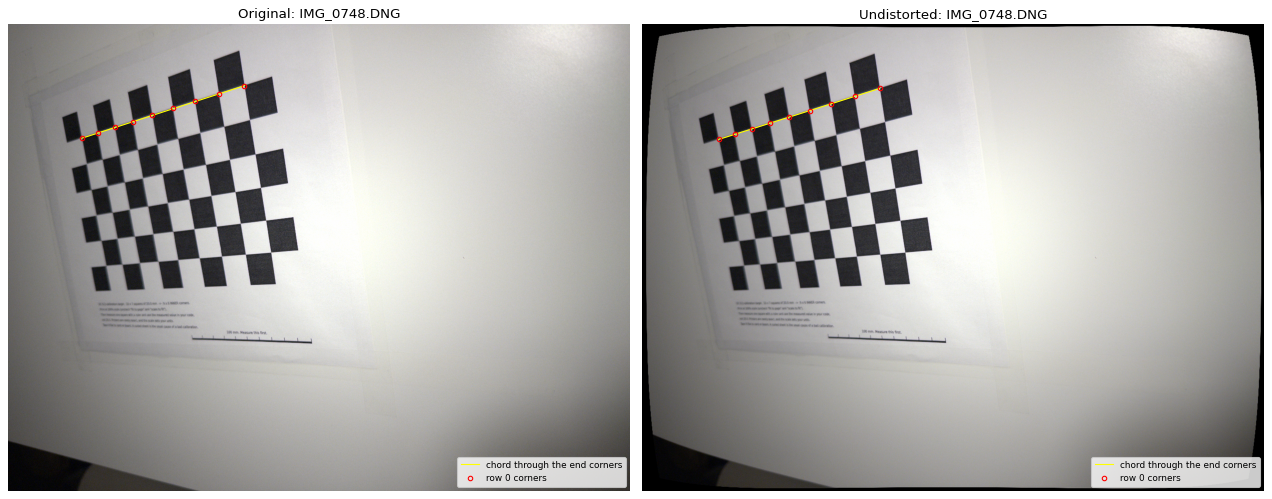

In [7]:
def line_fit(pts):
    """Total-least-squares line through 2-D points. Returns (centroid, unit direction, unit normal)."""
    pts = np.asarray(pts, dtype=np.float64).reshape(-1, 2)
    c = pts.mean(axis=0)
    _, _, vt = np.linalg.svd(pts - c)
    return c, vt[0], vt[1]


def perp_dev(pts):
    """Signed perpendicular distance of each point from its own best-fit line."""
    c, _, n = line_fit(pts)
    return (np.asarray(pts, dtype=np.float64).reshape(-1, 2) - c) @ n


def undistort_pts(pts):
    """Distorted pixel coordinates -> undistorted pixel coordinates in the same camera matrix."""
    return cv2.undistortPoints(np.asarray(pts, np.float32).reshape(-1, 1, 2), K, dist, P=K).reshape(-1, 2)


# A straight line is bent most by radial distortion when it runs across a radius far from the
# principal point. Score every row of every view by the distance from (cx, cy) to its fitted line.
half_diag = 0.5 * np.hypot(*image_size)
rows = []
for n in used_names:
    grid = all_corners[n].reshape(PATTERN[1], PATTERN[0], 2)
    for r in range(PATTERN[1]):
        c, _, nrm = line_fit(grid[r])
        rows.append({"file": n, "row": r, "dist_from_center": abs((c - [cx, cy]) @ nrm) / half_diag})
rows = pd.DataFrame(rows)
best = rows.loc[rows.dist_from_center.idxmax()]
EDGE_VIEW, EDGE_ROW = best.file, int(best.row)
print(f"Row {EDGE_ROW} of {EDGE_VIEW} lies {best.dist_from_center:.0%} of the half-diagonal from the principal point")

edge_image_path = Path(STRAIGHT_EDGE_FILE) if STRAIGHT_EDGE_FILE else CAL_DIR / EDGE_VIEW
rgb = load_rgb(edge_image_path)
rgb_ud = cv2.undistort(rgb, K, dist)

row_before = all_corners[EDGE_VIEW].reshape(PATTERN[1], PATTERN[0], 2)[EDGE_ROW]
row_after = undistort_pts(row_before)

DISPLAY_STEP = 3     # show every 3rd pixel; the figure cannot resolve more and the notebook stays small
extent = (-0.5, image_size[0] - 0.5, image_size[1] - 0.5, -0.5)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2), dpi=80)
for ax, img, pts, title in ((axes[0], rgb, row_before, "Original"),
                            (axes[1], rgb_ud, row_after, "Undistorted")):
    ax.imshow(img[::DISPLAY_STEP, ::DISPLAY_STEP], extent=extent)
    if not STRAIGHT_EDGE_FILE:
        ax.plot(pts[[0, -1], 0], pts[[0, -1], 1], "-", color="yellow", lw=1,
                label="chord through the end corners")
        ax.plot(pts[:, 0], pts[:, 1], "o", ms=4, mfc="none", color="red", label=f"row {EDGE_ROW} corners")
        ax.legend(loc="lower right", fontsize=8)
    ax.set_title(f"{title}: {edge_image_path.name}")
    ax.axis("off")
fig.tight_layout()
plt.show()

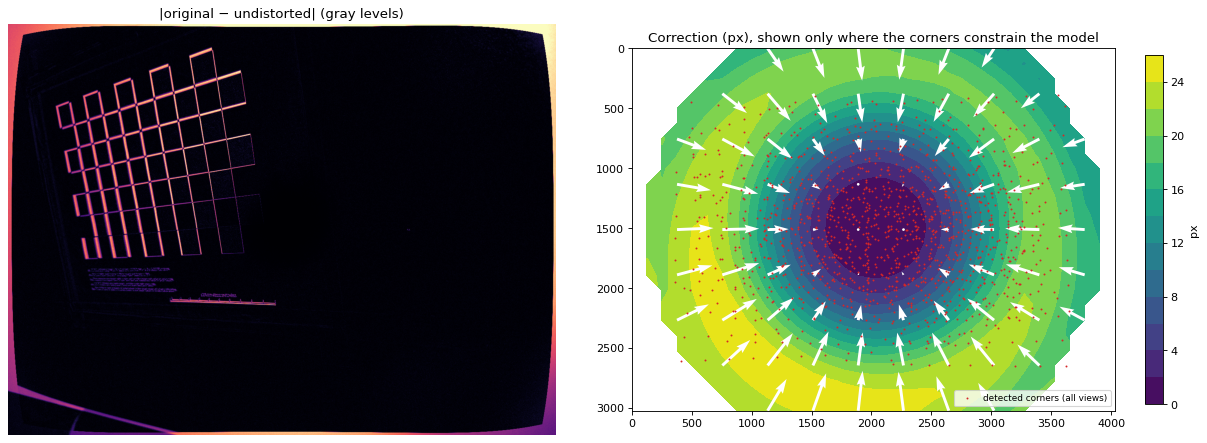

Detected corners reach normalized radius 0.676; the frame corners are at 0.872 (78% of the way out).
Largest correction inside the covered radius: 25.4 px


In [8]:
# The correction is a few pixels on a 4032-pixel frame, so it is invisible at full size.
# Difference image: anything that moved shows up, and it grows toward the corners.
diff = np.abs(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(float)
              - cv2.cvtColor(rgb_ud, cv2.COLOR_RGB2GRAY).astype(float))
# The fitted radial polynomial is only constrained where checkerboard corners were detected.
# Beyond that radius it is extrapolation, and it can fold over (stop increasing with radius),
# after which no undistorted point maps there at all. So report coverage, and draw the
# correction only inside the radius the corners actually reached.
def norm_radius(pts):
    pts = np.asarray(pts, dtype=np.float64).reshape(-1, 2)
    return np.hypot((pts[:, 0] - cx) / fx, (pts[:, 1] - cy) / fy)

corner_pts = np.concatenate([all_corners[n].reshape(-1, 2) for n in used_names])
r_covered = norm_radius(corner_pts).max()
r_frame = norm_radius([[0, 0], [image_size[0] - 1, 0], [0, image_size[1] - 1],
                       [image_size[0] - 1, image_size[1] - 1]]).max()
rr = np.linspace(0, 1.5, 3001)
r_dist = rr * (1 + k1 * rr ** 2 + k2 * rr ** 4 + k3 * rr ** 6)
fold = rr[np.argmax(r_dist)] if np.any(np.diff(r_dist) < 0) else None

gx, gy = np.meshgrid(np.linspace(0, image_size[0] - 1, 33), np.linspace(0, image_size[1] - 1, 25))
grid_pts = np.c_[gx.ravel(), gy.ravel()]
shift = undistort_pts(grid_pts) - grid_pts
inside = (norm_radius(grid_pts) <= r_covered).reshape(gx.shape)
mag = np.where(inside, np.hypot(*shift.T).reshape(gx.shape), np.nan)
sx = np.where(inside, shift[:, 0].reshape(gx.shape), np.nan)
sy = np.where(inside, shift[:, 1].reshape(gx.shape), np.nan)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), dpi=80)
axes[0].imshow(diff[::DISPLAY_STEP, ::DISPLAY_STEP], cmap="magma", vmax=np.percentile(diff, 99.5), extent=extent)
axes[0].set_title("|original − undistorted| (gray levels)")
axes[0].axis("off")
cs = axes[1].contourf(gx, gy, mag, levels=12, cmap="viridis")
axes[1].quiver(gx[::3, ::3], gy[::3, ::3], sx[::3, ::3], sy[::3, ::3], color="w", angles="xy")
axes[1].plot(corner_pts[:, 0], corner_pts[:, 1], ".", ms=1.5, color="tab:red", label="detected corners (all views)")
axes[1].set_xlim(0, image_size[0]); axes[1].set_ylim(image_size[1], 0)
axes[1].set_aspect("equal")
axes[1].set_title("Correction (px), shown only where the corners constrain the model")
axes[1].legend(loc="lower right", fontsize=8)
fig.colorbar(cs, ax=axes[1], shrink=0.85, label="px")
fig.tight_layout()
plt.show()
print(f"Detected corners reach normalized radius {r_covered:.3f}; the frame corners are at {r_frame:.3f} "
      f"({100 * r_covered / r_frame:.0f}% of the way out).")
if fold is not None:
    print(f"The fitted radial polynomial folds over at normalized radius {fold:.3f} (distorted {r_dist.max():.3f}); "
          f"no undistorted point maps beyond that, so the image there is extrapolation.")
print(f"Largest correction inside the covered radius: {np.nanmax(mag):.1f} px")

### Problem 3: Quantify that correction. Fit a straight line through one row of detected checkerboard corners and report the maximum perpendicular deviation of those corners from the fitted line, in pixels, before and after undistortion.
_Deliverable: Two deviation values in pixels._

IMG_0748.DNG, row 0 (9 corners), total-least-squares line fit
  max |perpendicular deviation| before undistortion: 1.354 px
  max |perpendicular deviation| after  undistortion: 0.686 px
  all 150 rows of all views, median before / after: 1.362 / 0.518 px


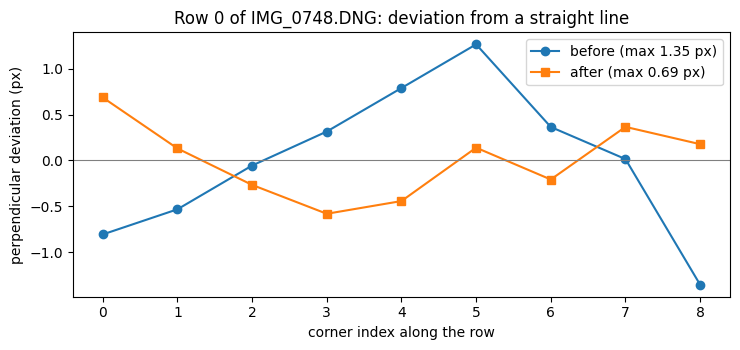

In [9]:
dev_before = perp_dev(row_before)
dev_after = perp_dev(row_after)

print(f"{EDGE_VIEW}, row {EDGE_ROW} ({PATTERN[0]} corners), total-least-squares line fit")
print(f"  max |perpendicular deviation| before undistortion: {np.abs(dev_before).max():.3f} px")
print(f"  max |perpendicular deviation| after  undistortion: {np.abs(dev_after).max():.3f} px")

# Context: the same statistic for every row of every view
all_before, all_after = [], []
for n in used_names:
    grid = all_corners[n].reshape(PATTERN[1], PATTERN[0], 2)
    for r in range(PATTERN[1]):
        all_before.append(np.abs(perp_dev(grid[r])).max())
        all_after.append(np.abs(perp_dev(undistort_pts(grid[r]))).max())
print(f"  all {len(all_before)} rows of all views, median before / after: "
      f"{np.median(all_before):.3f} / {np.median(all_after):.3f} px")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
pos = np.arange(PATTERN[0])
ax.plot(pos, dev_before, "o-", label=f"before (max {np.abs(dev_before).max():.2f} px)")
ax.plot(pos, dev_after, "s-", label=f"after (max {np.abs(dev_after).max():.2f} px)")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("corner index along the row")
ax.set_ylabel("perpendicular deviation (px)")
ax.set_title(f"Row {EDGE_ROW} of {EDGE_VIEW}: deviation from a straight line")
ax.legend()
fig.tight_layout()
plt.show()

### Problem 4: Compute your pixel pitch in micrometers as 1000 f_mm / f_px, where f_mm is the focal length recorded in the EXIF metadata and f_px is the mean of the two focal lengths in pixels from item 1. Then obtain it a second way, by a route that does not use your calibration at all: divide the 35 mm equivalent focal length in the EXIF by the actual focal length to get the crop factor, divide the 43.3 mm diagonal of 35 mm film by the crop factor to get your sensor diagonal, and divide that by the image diagonal in pixels.
_Deliverable: Both pitch values in micrometers, their percentage difference, and a statement of which you will use in Part 2 and why (2–3 sentences)._

In [10]:
ids = {lens_id(CAL_DIR / n) for n in used_names}
assert len(ids) == 1, f"Calibration frames came from more than one camera: {ids}"
print("Calibration camera:", next(iter(ids)))
print(f"EXIF: f = {F_EXIF_MM:.3f} mm, 35 mm equivalent = {F35_MM:.0f} mm, f/{N_EXIF:.2f}")

f_px = 0.5 * (fx + fy)
pitch_calib_um = 1000 * F_EXIF_MM / f_px

sensor_diag_mm = FILM_DIAG_MM / crop
diag_px = np.hypot(*image_size)
# pitch_exif_um was computed in item 1 from the same three numbers
assert np.isclose(pitch_exif_um, 1000 * sensor_diag_mm / diag_px)

pct = 100 * (pitch_calib_um - pitch_exif_um) / pitch_exif_um
pd.DataFrame({
    "route": ["1: 1000 f_mm / f_px (calibration)", "2: EXIF crop factor (no calibration)"],
    "inputs": [f"f_mm = {F_EXIF_MM:.3f} mm, f_px = {f_px:.1f} px",
               f"crop = {F35_MM:.0f}/{F_EXIF_MM:.3f} = {crop:.3f}, sensor diag = {sensor_diag_mm:.2f} mm, "
               f"image diag = {diag_px:.0f} px"],
    "pixel pitch (µm)": [pitch_calib_um, pitch_exif_um],
}).style.hide(axis="index").format({"pixel pitch (µm)": "{:.3f}"})

Calibration camera: ('iPhone 16 Pro Max back camera 6.765mm f/1.78', 6.765, 24, (4032, 3024))
EXIF: f = 6.765 mm, 35 mm equivalent = 24 mm, f/1.78


route,inputs,pixel pitch (µm)
1: 1000 f_mm / f_px (calibration),"f_mm = 6.765 mm, f_px = 2901.8 px",2.331
2: EXIF crop factor (no calibration),"crop = 24/6.765 = 3.548, sensor diag = 12.21 mm, image diag = 5040 px",2.422


In [11]:
print(f"Percentage difference (route 1 relative to route 2): {pct:+.1f}%")
# The 35 mm equivalent is stored as a whole number of mm, so route 2 carries up to ±0.5 mm of rounding
lo, hi = [1000 * FILM_DIAG_MM / ((F35_MM + d) / F_EXIF_MM) / diag_px for d in (0.5, -0.5)]
print(f"Route 2 range from rounding of the {F35_MM:.0f} mm equivalent: {lo:.3f} to {hi:.3f} µm")

# Choose the pitch used in Part 2. Set this once, before Part 2, and justify it below.
PITCH_CHOICE = "exif"          # "exif" (route 2) or "calibration" (route 1)
PIXEL_PITCH_UM = pitch_exif_um if PITCH_CHOICE == "exif" else pitch_calib_um
print(f"Using p = {PIXEL_PITCH_UM:.3f} µm ({PITCH_CHOICE}) in Part 2")

Percentage difference (route 1 relative to route 2): -3.7%
Route 2 range from rounding of the 24 mm equivalent: 2.372 to 2.473 µm
Using p = 2.422 µm (exif) in Part 2


### **Which pixel pitch value am I going to use in Part 2?**
**Route 1, from the calibration:** In the pinhole model, the focal length in pixels is the focal length in mm divided by the pitch: f_px = f_mm / p. So p = 1000 · f_mm / f_px = 1000 × 6.765 / 2901.8 = 2.331 µm

**Route 2, from the EXIF only:** The 24 mm “35 mm equivalent” says how much smaller the sensor is than 35 mm film: crop factor = 24 / 6.765 = 3.548. The sensor diagonal is 43.3 / 3.548 = 12.21 mm. The image diagonal is √(4032² + 3024²) = 5040 px, so p = 12.21 mm / 5040 = 2.422 µm

**I will be using Route 2, from the EXIF only.** This route results in a value closer to the documented pixel size:
* The iPhone 16 Pro Max main sensor has 48 megapixels at 1.22 μm each [[1]](#ref1), [[2]](#ref2).
* The iPhone 16 Pro Max contains "Quad Pixel" technology, where 2×2 groups of pixels are combined into one larger pixel to increase light sensitivity. Apple gives 2.44 μm for these quad pixels [[1]](#ref1). My raw files are 4032 × 3024 (12 MP), so they are recorded at this binned pitch.

Relative to 2.44 μm, Route 2 differs by about −0.74 % and Route 1 by about −4.47 %.

**References**

<a id="ref1"></a>[1] Macwelt, "iPhone 16 Pro: Kamera" (in German). https://www.macwelt.de/article/2454022/iphone-16-pro-kamera-2.html

<a id="ref2"></a>[2] PhoneArena, "Apple iPhone 16 Pro Max specs." https://www.phonearena.com/phones/Apple-iPhone-16-Pro-Max_id12238

## Part 2: Predicted Response

λ = 0.55 µm, N = the f-number in the EXIF, p = the pixel pitch from item 4. Every frequency is in cycles per micrometer. The green plane of the Bayer mosaic is sampled at 2p, so its Nyquist frequency is 1/(4p), while the photodiode aperture is still p.

* Diffraction: MTF_d(ν) = (2/π)[arccos(s) − s√(1 − s²)], s = ν/ν_c, ν_c = 1/(λN)
* Photodiode aperture: MTF_p(ν) = |sinc(νp)|, sinc(x) = sin(πx)/(πx)
* Predicted response: MTF_d · MTF_p

### Problem 5: Compute the diffraction cutoff ν_c, the green-plane Nyquist frequency, and the ratio of the two.
_Deliverable: Three values, each in cycles per micrometer and in cycles per millimeter._

In [12]:
p_um = PIXEL_PITCH_UM
N = N_EXIF
lam = WAVELENGTH_UM

nu_c = 1 / (lam * N)                 # diffraction cutoff, cycles/µm
nu_nyq_green = 1 / (4 * p_um)        # green plane sampled at 2p
ratio = nu_c / nu_nyq_green

print(f"p = {p_um:.3f} µm, N = f/{N:.3f}, λ = {lam} µm")
pd.DataFrame({
    "quantity": ["diffraction cutoff ν_c = 1/(λN)", "green-plane Nyquist 1/(4p)", "ratio ν_c / Nyquist"],
    "cycles/µm": [nu_c, nu_nyq_green, ratio],
    "cycles/mm": [1000 * nu_c, 1000 * nu_nyq_green, ratio],
}).style.hide(axis="index").format({"cycles/µm": "{:.4f}", "cycles/mm": "{:.1f}"})

p = 2.422 µm, N = f/1.780, λ = 0.55 µm


quantity,cycles/µm,cycles/mm
diffraction cutoff ν_c = 1/(λN),1.0215,1021.5
green-plane Nyquist 1/(4p),0.1032,103.2
ratio ν_c / Nyquist,9.8944,9.9


_The ratio is dimensionless, so it is the same in both columns._

### Problem 6: State whether diffraction or sampling is the binding limit for your camera, and find the f-number at which that answer would change by setting the diffraction cutoff equal to the full-sensor Nyquist frequency 1/(2p) and solving for N.
_Deliverable: The crossover f-number and a written explanation (2–4 sentences)._

In [13]:
nu_nyq_full = 1 / (2 * p_um)
# 1/(λ N) = 1/(2p)  ->  N = 2p/λ
N_cross = 2 * p_um / lam
print(f"Full-sensor Nyquist 1/(2p) = {nu_nyq_full:.4f} cycles/µm ({1000 * nu_nyq_full:.1f} cycles/mm)")
print(f"Diffraction cutoff at f/{N:.2f}: {nu_c:.4f} cycles/µm = {nu_c / nu_nyq_full:.1f} × full-sensor Nyquist, "
      f"{nu_c / nu_nyq_green:.1f} × green-plane Nyquist")
print(f"Crossover f-number N = 2p/λ = {N_cross:.2f}")
print(f"Binding limit at f/{N:.2f}: {'sampling' if nu_c > nu_nyq_full else 'diffraction'}")

Full-sensor Nyquist 1/(2p) = 0.2065 cycles/µm (206.5 cycles/mm)
Diffraction cutoff at f/1.78: 1.0215 cycles/µm = 4.9 × full-sensor Nyquist, 9.9 × green-plane Nyquist
Crossover f-number N = 2p/λ = 8.81
Binding limit at f/1.78: sampling


### **Which limit binds: diffraction or sampling?**
**Diffraction limit:** The lens cannot pass any detail finer than its cutoff frequency ν_c = 1/(λN). At f/1.78, ν_c = 1/(0.55 × 1.78) = 1.0215 cycles/µm.

**Sampling limit:** The sensor cannot record detail finer than its Nyquist frequency, half the sampling rate. With pixels p = 2.422 µm apart, the full-sensor Nyquist frequency is 1/(2p) = 0.2065 cycles/µm (0.1032 cycles/µm for one green plane).

**Sampling is the binding limit for my camera.** The lens passes detail up to 4.9 times the full-sensor Nyquist frequency (9.9 times the green-plane Nyquist), so the pixels discard fine detail long before diffraction removes it.

**Crossover f-number:** Setting 1/(λN) = 1/(2p) and solving gives N = 2p/λ = 2 × 2.422 / 0.55 = 8.81. Diffraction would only become the binding limit at about f/8.8 or slower, and the iPhone's main camera has a fixed f/1.78 aperture, so on this camera the pixel pitch, not diffraction, caps the resolution.

### Problem 7: Plot MTF_d(ν), MTF_p(ν), and their product from zero to ν_c, with a vertical line marking the green-plane Nyquist frequency. Report the value of the product at that frequency.
_Deliverable: Figure with labeled axes, and the predicted modulation at Nyquist._

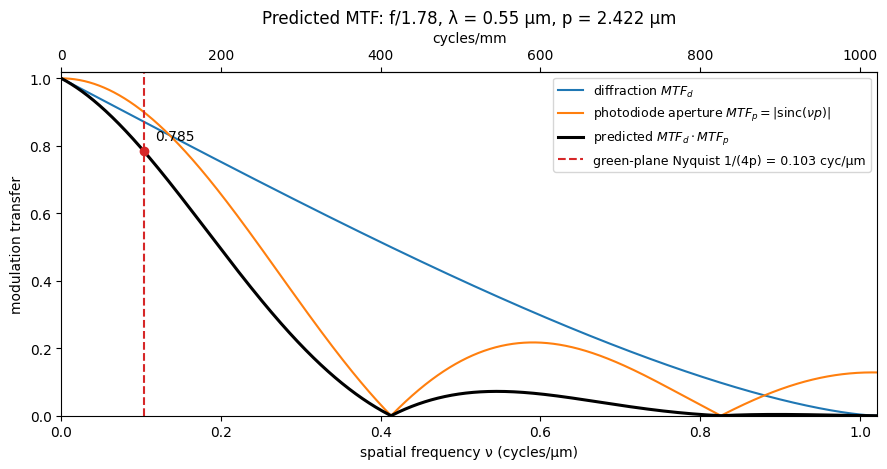

At the green-plane Nyquist frequency (0.1032 cyc/µm): MTF_d = 0.872, MTF_p = 0.900, product = 0.785


In [14]:
def mtf_diffraction(nu, nu_c=nu_c):
    s = np.clip(np.asarray(nu, dtype=float) / nu_c, 0, 1)
    return (2 / np.pi) * (np.arccos(s) - s * np.sqrt(1 - s ** 2))


def mtf_pixel(nu, p=p_um):
    return np.abs(np.sinc(np.asarray(nu, dtype=float) * p))     # np.sinc(x) = sin(πx)/(πx)


def mtf_predicted(nu):
    return mtf_diffraction(nu) * mtf_pixel(nu)


nu = np.linspace(0, nu_c, 2000)
mtf_at_nyq = float(mtf_predicted(nu_nyq_green))

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(nu, mtf_diffraction(nu), label=r"diffraction $MTF_d$")
ax.plot(nu, mtf_pixel(nu), label=r"photodiode aperture $MTF_p = |\mathrm{sinc}(\nu p)|$")
ax.plot(nu, mtf_predicted(nu), "k", lw=2.2, label=r"predicted $MTF_d \cdot MTF_p$")
ax.axvline(nu_nyq_green, color="tab:red", ls="--",
           label=f"green-plane Nyquist 1/(4p) = {nu_nyq_green:.3f} cyc/µm")
ax.plot([nu_nyq_green], [mtf_at_nyq], "o", color="tab:red")
ax.annotate(f"{mtf_at_nyq:.3f}", (nu_nyq_green, mtf_at_nyq), xytext=(8, 8), textcoords="offset points")
ax.set_xlim(0, nu_c)
ax.set_ylim(0, 1.02)
ax.set_xlabel("spatial frequency ν (cycles/µm)")
ax.set_ylabel("modulation transfer")
ax.set_title(f"Predicted MTF: f/{N:.2f}, λ = {lam} µm, p = {p_um:.3f} µm")
sec = ax.secondary_xaxis("top", functions=(lambda v: 1000 * v, lambda v: v / 1000))
sec.set_xlabel("cycles/mm")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"At the green-plane Nyquist frequency ({nu_nyq_green:.4f} cyc/µm): "
      f"MTF_d = {float(mtf_diffraction(nu_nyq_green)):.3f}, MTF_p = {float(mtf_pixel(nu_nyq_green)):.3f}, "
      f"product = {mtf_at_nyq:.3f}")

### Problem 8: Determine the frequency at which the predicted response falls to 0.5, which is your predicted MTF50. If it lies above the Nyquist frequency, explain what that implies about aliasing and about which physical effect will actually set the MTF50 you measure in Part 4.
_Deliverable: Predicted MTF50 in cycles per micrometer, and a written interpretation (2–4 sentences)._

In [15]:
# The product is monotonic below the first zero of the sinc (ν = 1/p) and of the diffraction term (ν_c)
upper = min(nu_c, 1 / p_um) * 0.999
mtf50_pred = brentq(lambda v: mtf_predicted(v) - 0.5, 1e-9, upper)
mtf50_pred_gp = mtf50_pred * 2 * p_um          # cycles per green-plane pixel (pixel spacing 2p)

print(f"Predicted MTF50 = {mtf50_pred:.4f} cycles/µm = {1000 * mtf50_pred:.1f} cycles/mm "
      f"= {mtf50_pred_gp:.3f} cycles per green-plane pixel")
print(f"Ratio to the green-plane Nyquist frequency: {mtf50_pred / nu_nyq_green:.2f}")

# Freeze the prediction. The assignment forbids revising it after measuring, so the file is written
# once and never overwritten; delete it by hand only if Part 2 was genuinely wrong before measuring.
prediction = {
    "written": datetime.now().isoformat(timespec="seconds"),
    "pixel_pitch_um": p_um, "pitch_choice": PITCH_CHOICE, "f_number": N, "wavelength_um": lam,
    "nu_c_cyc_per_um": nu_c, "nyquist_green_cyc_per_um": nu_nyq_green, "crossover_N": N_cross,
    "mtf_at_green_nyquist": mtf_at_nyq, "mtf50_cyc_per_um": mtf50_pred,
    "mtf50_cyc_per_green_px": mtf50_pred_gp,
}
if PREDICTION_FILE.exists():
    frozen = json.loads(PREDICTION_FILE.read_text())
    changed = {k: (frozen.get(k), v) for k, v in prediction.items()
               if isinstance(v, float) and not np.isclose(frozen.get(k, np.nan), v)}
    print(f"Prediction already frozen in {PREDICTION_FILE} on {frozen['written']}; not overwritten.")
    if changed:
        print("! These values differ from the frozen prediction:", changed)
else:
    PREDICTION_FILE.write_text(json.dumps(prediction, indent=2))
    print(f"Prediction frozen in {PREDICTION_FILE}")

Predicted MTF50 = 0.1980 cycles/µm = 198.0 cycles/mm = 0.959 cycles per green-plane pixel
Ratio to the green-plane Nyquist frequency: 1.92
Prediction already frozen in hw2_predictions.json on 2026-11-11T23:04:20; not overwritten.


### **What is the predicted MTF50, and what does it mean?**
**MTF:** The modulation transfer function says how much of a pattern's contrast survives the camera at each spatial frequency: 1 means all of it survives, 0 means none.

**MTF_d(ν), diffraction:** Light passing through the lens's circular aperture spreads into a small blur spot (the Airy pattern). MTF_d is the MTF of that blur. It falls almost linearly from 1 at ν = 0 to 0 at the cutoff ν_c = 1.0215 cycles/µm.

**MTF_p(ν), photodiode aperture:** Each pixel averages all the light that lands across its width p = 2.422 µm, which blurs detail finer than a pixel. Averaging over a width p is a boxcar, whose MTF is |sinc(νp)|; it first reaches 0 at ν = 1/p = 0.413 cycles/µm.

**Their product:** The lens blurs the light first and the pixel then averages it, so the two blurs act in series and their MTFs multiply. At the green-plane Nyquist frequency (0.1032 cycles/µm) the product is 0.872 × 0.900 = 0.785.

**Why MTF50:** MTF50 is the frequency at which contrast falls to half. It is a single number that tracks perceived sharpness well, and it sits where the MTF curve is steep, so it can be measured reliably even with noise. That makes it the standard figure of merit for comparing cameras and lenses.

**Predicted MTF50 = 0.1980 cycles/µm (198.0 cycles/mm), or 0.959 cycles per green-plane pixel: 1.92 times the green-plane Nyquist frequency.**

**Aliasing:** The predicted response still keeps 78.5 % of the contrast at Nyquist and does not fall to 50 % until almost twice Nyquist, so scene detail above Nyquist reaches the sensor with strong contrast. One green plane cannot represent that detail, so it folds back to lower frequencies as false patterns (aliasing and moiré), and the phone has no optical low-pass filter to remove it.

**What will set the measured MTF50:** Sampling will not, because the slanted-edge method combines many rows to sample the edge finely and so measures the blur before sampling, past Nyquist. Of the two modelled effects, the photodiode aperture dominates: on its own it would give an MTF50 of 0.249 cycles/µm, against 0.413 cycles/µm for diffraction alone. The measured value will likely be lower still, because real lens aberrations and focus error, which the prediction leaves out, add blur of their own.

## Part 3: Validating the Measurement

For a Gaussian point spread function of standard deviation σ, the MTF is exp(−2π²σ²f²), which falls to 0.5 at f = [ln 2 / (2π²σ²)]^½ cycles per pixel: 0.187 for σ = 1.0.

### Problem 9: Generate a synthetic slanted edge by tilting a step edge 5 degrees, convolving it with a Gaussian point spread function of standard deviation 1.0 pixel, and sampling the result on a pixel grid.
_Deliverable: Image of the simulated capture._

Simulated capture (128, 96), edge at 5.0°, σ = 1.0 px
Max difference from the closed-form erf edge: 2.52e-04 (of a 0.70 step)


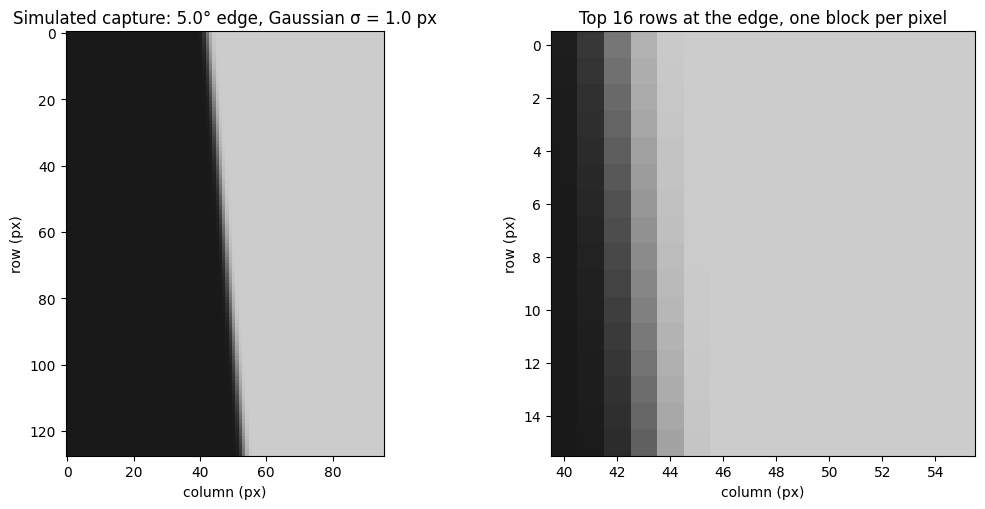

In [16]:
SIM_SIGMA = 1.0          # Gaussian PSF, pixels
SIM_ANGLE = 5.0          # degrees from vertical
SIM_SHAPE = (128, 96)    # rows, columns
SIM_DARK, SIM_LIGHT = 0.10, 0.80     # linear signal levels either side of the edge
FINE = 15                # odd, so every pixel centre falls exactly on a fine-grid sample


def synthetic_edge(shape=SIM_SHAPE, angle_deg=SIM_ANGLE, sigma=SIM_SIGMA, fine=FINE,
                   dark=SIM_DARK, light=SIM_LIGHT):
    """Step edge tilted by angle_deg, convolved with a Gaussian PSF, point-sampled at pixel centres.

    The step is drawn on a grid `fine` times finer than the pixels, blurred there with a Gaussian of
    sigma*fine fine-grid samples, and then read out at the pixel centres. No pixel aperture is
    applied, so the analytic MTF is exactly the Gaussian's."""
    h, w = shape
    t = np.tan(np.deg2rad(angle_deg))
    # fine-grid coordinates in pixel units; pixel (i, j) centre is at (i, j)
    yf = (np.arange(h * fine) - (fine - 1) / 2) / fine
    xf = (np.arange(w * fine) - (fine - 1) / 2) / fine
    X, Y = np.meshgrid(xf, yf)
    x_edge = (w - 1) / 2 + t * (Y - (h - 1) / 2)
    step = np.where(X > x_edge, light, dark)
    blurred = cv2.GaussianBlur(step, (0, 0), sigmaX=sigma * fine, sigmaY=sigma * fine,
                               borderType=cv2.BORDER_REPLICATE)
    sampled = blurred[(fine - 1) // 2::fine, (fine - 1) // 2::fine]

    # Closed form for the same thing, as a check: a Gaussian-blurred step is an error function
    # of the perpendicular distance to the edge.
    yy, xx = np.mgrid[0:h, 0:w]
    d = (xx - ((w - 1) / 2 + t * (yy - (h - 1) / 2))) * np.cos(np.deg2rad(angle_deg))
    analytic = dark + (light - dark) * 0.5 * (1 + erf(d / (np.sqrt(2) * sigma)))
    return sampled, analytic


sim_edge, sim_analytic = synthetic_edge()
err = np.abs(sim_edge - sim_analytic)
print(f"Simulated capture {sim_edge.shape}, edge at {SIM_ANGLE}°, σ = {SIM_SIGMA} px")
print(f"Max difference from the closed-form erf edge: {err[8:-8, 8:-8].max():.2e} "
      f"(of a {SIM_LIGHT - SIM_DARK:.2f} step)")

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
axes[0].imshow(sim_edge, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Simulated capture: {SIM_ANGLE}° edge, Gaussian σ = {SIM_SIGMA} px")
axes[0].set_xlabel("column (px)"); axes[0].set_ylabel("row (px)")
zoom = sim_edge[:16, SIM_SHAPE[1] // 2 - 8:SIM_SHAPE[1] // 2 + 8]
axes[1].imshow(zoom, cmap="gray", vmin=0, vmax=1,
               extent=(SIM_SHAPE[1] // 2 - 8.5, SIM_SHAPE[1] // 2 + 7.5, 15.5, -0.5))
axes[1].set_title("Top 16 rows at the edge, one block per pixel")
axes[1].set_xlabel("column (px)"); axes[1].set_ylabel("row (px)")
fig.tight_layout()
plt.show()

### Problem 10: Measure the modulation transfer function of that simulated capture with the code you will use on your own photographs.
_Deliverable: Figures of the edge spread function, the line spread function, and the modulation transfer function._

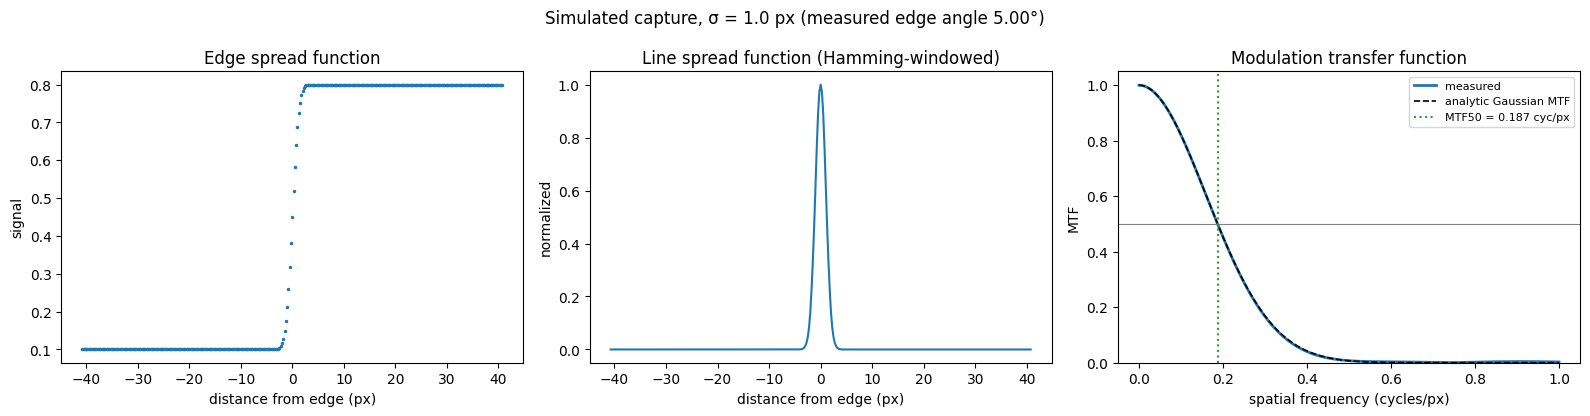

In [17]:
def slanted_edge_mtf(roi, oversample=4, correct=True, f_max=1.0):
    """Slanted-edge MTF (after ISO 12233). Returns a dict with the ESF, LSF, MTF and MTF50.

    roi        : 2-D array, linear signal, containing one straight edge a few degrees off vertical
                 or off horizontal (a near-horizontal edge is transposed).
    oversample : ESF bins per pixel.
    correct    : divide out the two transfer functions the procedure itself adds, the boxcar of
                 the 1/oversample bins and the 3-point central difference.
    Frequencies are in cycles per pixel of `roi`, measured along the edge normal.
    """
    roi = np.asarray(roi, dtype=np.float64)
    transposed = np.abs(np.diff(roi, axis=0)).sum() > np.abs(np.diff(roi, axis=1)).sum()
    if transposed:
        roi = roi.T
    h, w = roi.shape
    x = np.arange(w, dtype=np.float64)
    y = np.arange(h, dtype=np.float64)

    # 1. Edge location in each row: centroid of the derivative, refined twice with a Hamming
    #    window centred on the previous line fit so that noise far from the edge is ignored.
    deriv = np.abs(np.gradient(roi, axis=1))
    weights = np.ones_like(deriv)
    for _ in range(3):
        cent = (deriv * weights * x).sum(axis=1) / (deriv * weights).sum(axis=1)
        slope, icpt = np.polyfit(y, cent, 1)
        xe = slope * y + icpt
        half = min(xe.min(), w - 1 - xe.max())
        weights = np.clip(0.54 + 0.46 * np.cos(np.pi * (x[None, :] - xe[:, None]) / max(half, 2)), 0, None)
        weights[np.abs(x[None, :] - xe[:, None]) > half] = 0
    angle = np.degrees(np.arctan(slope))

    # 2. Project every pixel onto the edge normal and bin at 1/oversample pixel
    cos_t = 1 / np.sqrt(1 + slope ** 2)
    dist = (x[None, :] - xe[:, None]) * cos_t
    reach = min(xe.min(), w - 1 - xe.max()) * cos_t - 1      # distance covered in every row
    nb = int(np.floor(reach * oversample))
    idx = np.round(dist * oversample).astype(int)
    keep = np.abs(idx) <= nb
    sums = np.bincount(idx[keep] + nb, weights=roi[keep], minlength=2 * nb + 1)
    counts = np.bincount(idx[keep] + nb, minlength=2 * nb + 1)
    esf_x = np.arange(-nb, nb + 1) / oversample
    filled = counts > 0
    esf = np.interp(esf_x, esf_x[filled], sums[filled] / counts[filled])
    if esf[-oversample:].mean() < esf[:oversample].mean():        # make it rise left to right
        esf = esf[::-1]

    # 3. Line spread function by central difference, windowed symmetrically about its centroid
    lsf = np.zeros_like(esf)
    lsf[1:-1] = (esf[2:] - esf[:-2]) / 2
    centre = int(round((lsf * np.arange(lsf.size)).sum() / lsf.sum()))
    hw = min(centre, lsf.size - 1 - centre)
    seg = lsf[centre - hw:centre + hw + 1] * np.hamming(2 * hw + 1)
    lsf_x = esf_x[centre - hw:centre + hw + 1]

    # 4. MTF, normalized at zero frequency
    nfft = max(1024, 1 << int(np.ceil(np.log2(seg.size)) + 2))
    spec = np.abs(np.fft.rfft(seg, n=nfft))
    freq = np.fft.rfftfreq(nfft, d=1 / oversample)               # cycles per pixel
    mtf_raw = spec / spec[0]
    delta = 1 / oversample
    procedure = np.abs(np.sinc(freq * delta) * np.sinc(2 * freq * delta))   # bin boxcar × central difference
    mtf_corr = mtf_raw / procedure
    sel = freq <= f_max
    freq, mtf_raw, mtf_corr = freq[sel], mtf_raw[sel], mtf_corr[sel]
    mtf = mtf_corr if correct else mtf_raw

    def mtf50_of(m):
        below = np.nonzero(m < 0.5)[0]
        if below.size == 0:
            return np.nan
        i = below[0]
        return freq[i - 1] + (0.5 - m[i - 1]) * (freq[i] - freq[i - 1]) / (m[i] - m[i - 1])

    return {"freq": freq, "mtf": mtf, "mtf_raw": mtf_raw, "mtf_corrected": mtf_corr,
            "mtf50": mtf50_of(mtf), "mtf50_raw": mtf50_of(mtf_raw), "mtf50_corrected": mtf50_of(mtf_corr),
            "esf_x": esf_x, "esf": esf, "lsf_x": lsf_x, "lsf": seg / seg.max(),
            "angle_deg": angle, "transposed": transposed, "samples_per_bin": counts[filled].mean()}


def mtf_at(result, f):
    """Measured MTF interpolated at frequency f (cycles per pixel of the ROI)."""
    return float(np.interp(f, result["freq"], result["mtf"]))


def plot_sfr(res, title, unit="px", f_mark=None, f_mark_label=None, extra=None):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    axes[0].plot(res["esf_x"], res["esf"], ".", ms=3)
    axes[0].set_xlabel(f"distance from edge ({unit})"); axes[0].set_ylabel("signal")
    axes[0].set_title("Edge spread function")
    axes[1].plot(res["lsf_x"], res["lsf"], "-")
    axes[1].set_xlabel(f"distance from edge ({unit})"); axes[1].set_ylabel("normalized")
    axes[1].set_title("Line spread function (Hamming-windowed)")
    axes[2].plot(res["freq"], res["mtf"], lw=2, label="measured")
    if extra is not None:
        axes[2].plot(*extra[:2], "k--", lw=1.2, label=extra[2])
    axes[2].axhline(0.5, color="gray", lw=0.8)
    axes[2].axvline(res["mtf50"], color="tab:green", ls=":", label=f"MTF50 = {res['mtf50']:.3f} cyc/{unit}")
    if f_mark is not None:
        axes[2].axvline(f_mark, color="tab:red", ls="--", label=f_mark_label)
    axes[2].set_xlabel(f"spatial frequency (cycles/{unit})"); axes[2].set_ylabel("MTF")
    axes[2].set_ylim(0, 1.05); axes[2].set_title("Modulation transfer function")
    axes[2].legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


sim_res = slanted_edge_mtf(sim_edge)
f_plot = sim_res["freq"]
plot_sfr(sim_res, f"Simulated capture, σ = {SIM_SIGMA} px (measured edge angle {sim_res['angle_deg']:.2f}°)",
         extra=(f_plot, np.exp(-2 * np.pi ** 2 * SIM_SIGMA ** 2 * f_plot ** 2), "analytic Gaussian MTF"))

### Problem 11: Compare the MTF50 your code reports against the analytic value above.
_Deliverable: Measured MTF50, analytic MTF50, and the percentage error._

In [18]:
mtf50_analytic = np.sqrt(np.log(2) / (2 * np.pi ** 2 * SIM_SIGMA ** 2))
pe = lambda m: 100 * (m - mtf50_analytic) / mtf50_analytic

rows = [("measured (corrected for binning and finite difference)", sim_res["mtf50_corrected"]),
        ("measured (uncorrected)", sim_res["mtf50_raw"])]

# Robustness checks, not required: noise at a level like a real capture, and a narrow window
rng = np.random.default_rng(513)
noisy = sim_edge + rng.normal(0, 0.01, sim_edge.shape)
rows.append(("measured, 1% noise added (corrected)", slanted_edge_mtf(noisy)["mtf50"]))
r0, c0 = SIM_SHAPE[0] // 2, SIM_SHAPE[1] // 2
narrow = sim_edge[r0 - 24:r0 + 24, c0 - 6:c0 + 6]       # 48 rows so the edge stays inside the 12 columns
rows.append(("measured, ROI only ±6 px across the edge (corrected)", slanted_edge_mtf(narrow)["mtf50"]))

val = pd.DataFrame(rows, columns=["case", "MTF50 (cycles/px)"])
val["analytic (cycles/px)"] = mtf50_analytic
val["error (%)"] = pe(val["MTF50 (cycles/px)"])
print(f"Analytic MTF50 for σ = {SIM_SIGMA} px: {mtf50_analytic:.4f} cycles/px")
print(f"Measured edge angle {sim_res['angle_deg']:.3f}° (drawn at {SIM_ANGLE}°), "
      f"{sim_res['samples_per_bin']:.0f} samples per ESF bin on average")
val.style.hide(axis="index").format({"MTF50 (cycles/px)": "{:.4f}", "analytic (cycles/px)": "{:.4f}",
                                     "error (%)": "{:+.2f}"})

Analytic MTF50 for σ = 1.0 px: 0.1874 cycles/px
Measured edge angle 4.999° (drawn at 5.0°), 32 samples per ESF bin on average


case,MTF50 (cycles/px),analytic (cycles/px),error (%)
measured (corrected for binning and finite difference),0.1872,0.1874,-0.12
measured (uncorrected),0.1848,0.1874,-1.39
"measured, 1% noise added (corrected)",0.1850,0.1874,-1.27
"measured, ROI only ±6 px across the edge (corrected)",0.2727,0.1874,+45.50


## Part 4: Measurement

Captures go in `Homework 2 Image Captures/Slanted Edge/` as Bayer raw DNGs (the same app and settings as the Exercise 1 captures, **not** ProRAW), at 1x, square-on, with nothing moved between frames. Until that folder has files, the cells below only print what is missing.

### Scale bar check ("100 mm. Measure this first.")

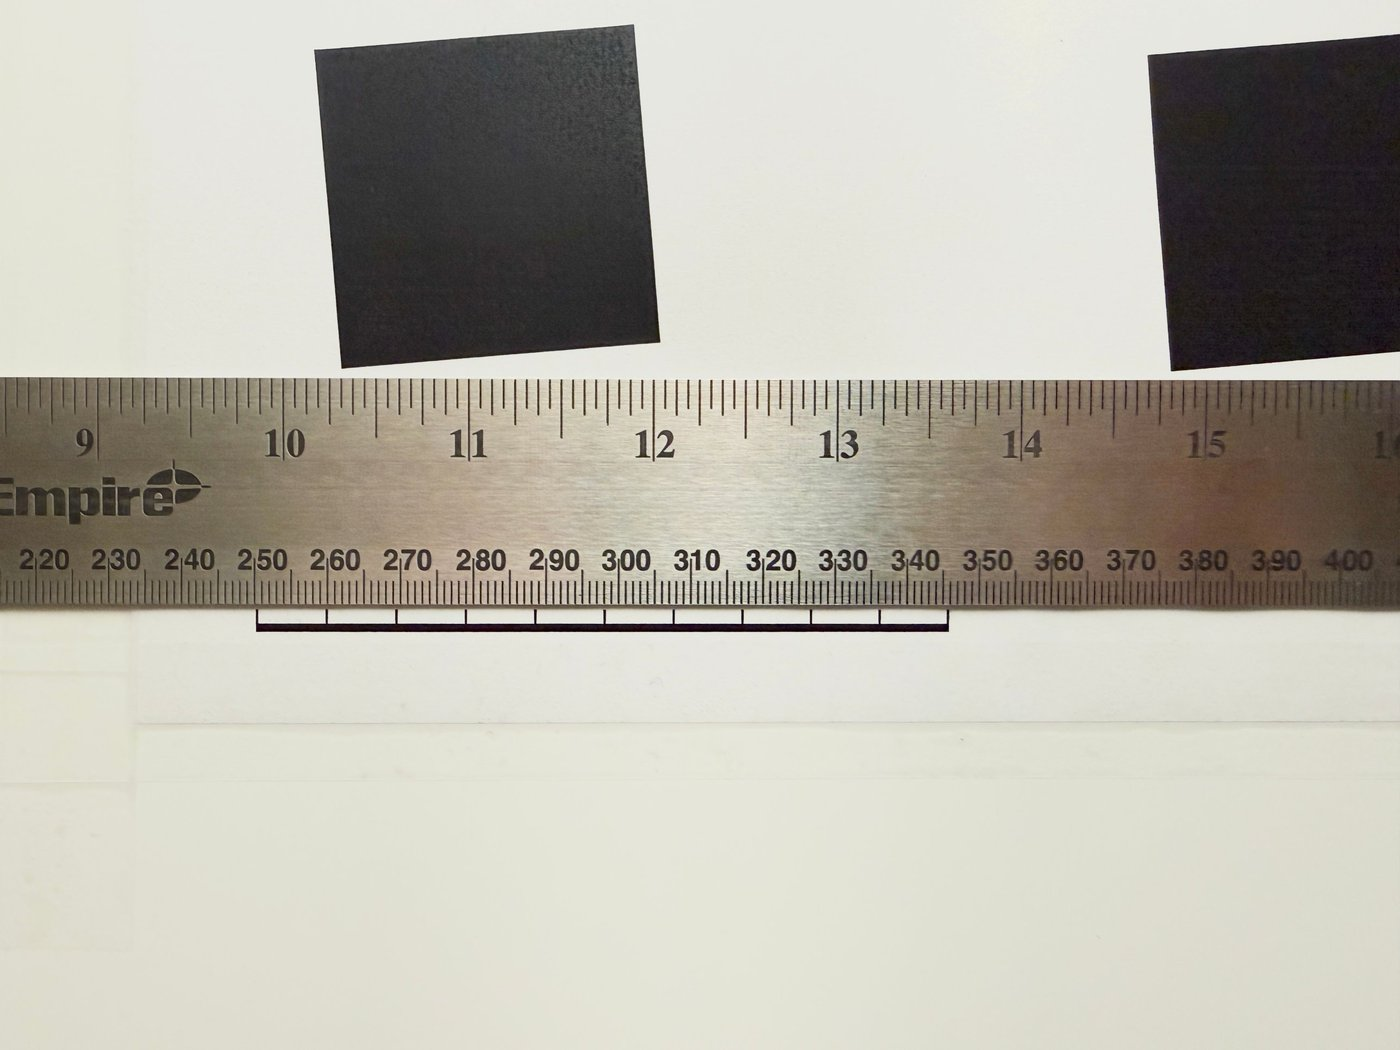

_Steel rule against the printed 100 mm scale bar._

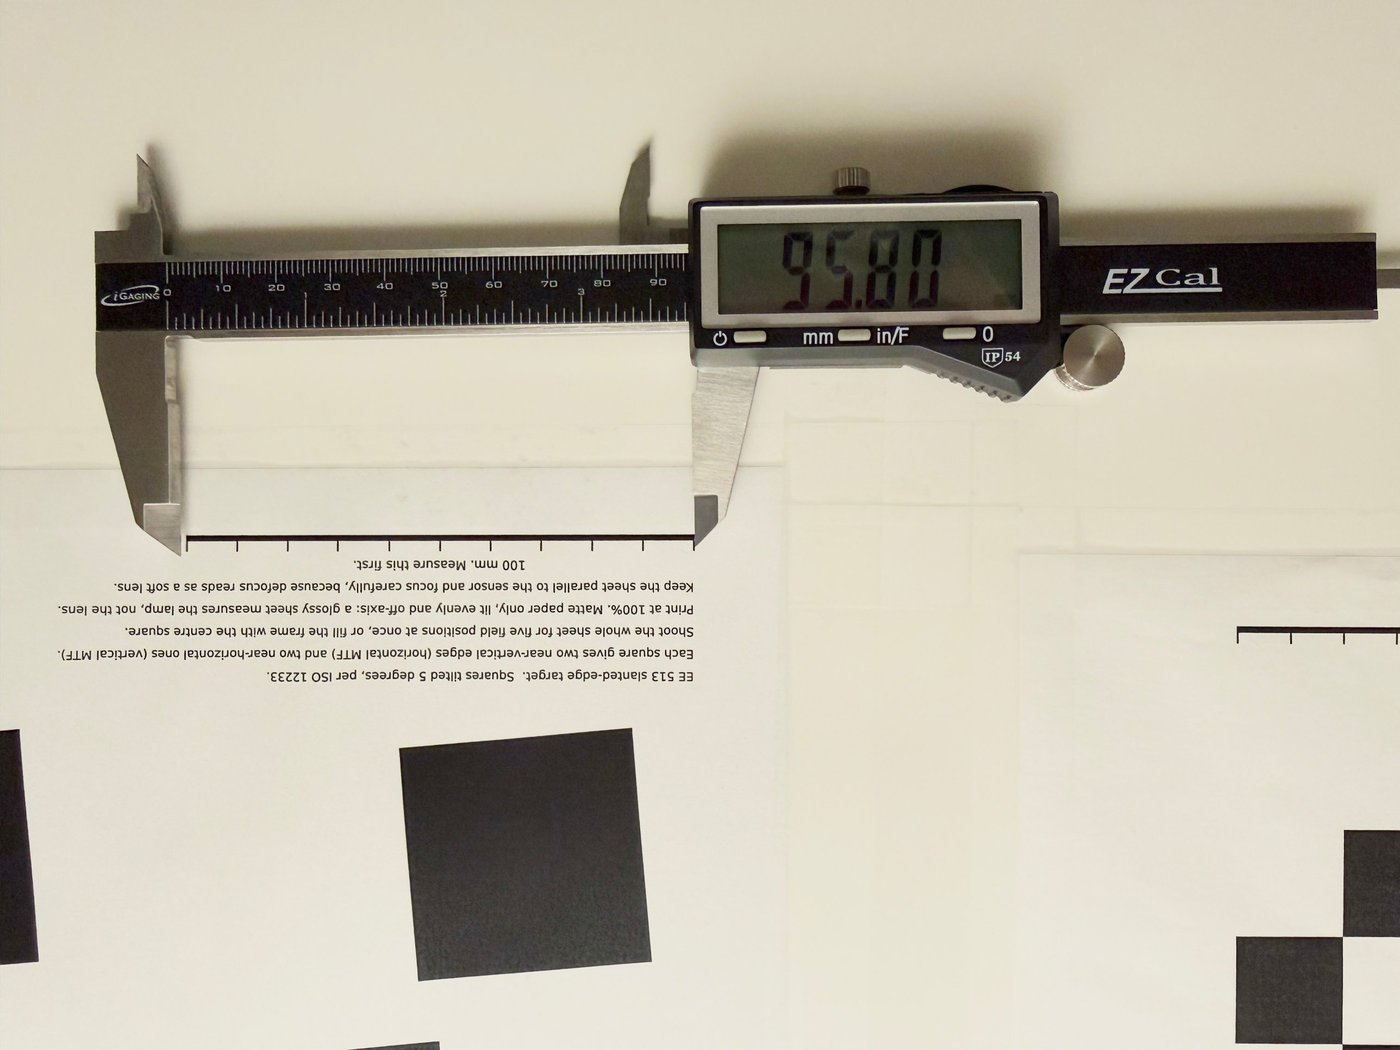

_Digital calipers on the printed 100 mm scale bar: 95.80 mm._

The printed 100 mm scale bar measured 95.80 mm with digital calipers (95.8 % scale), which does not affect the MTF: Part 4 is measured in units of the sensor, and a uniform rescaling leaves the 5° edge angle exactly as drawn.

### Problem 12: Print the slanted edge target, tape it flat, and illuminate it evenly and off axis so that no specular highlight falls on an edge. Capture it at least five times in raw at 1x, without moving the target between captures.
_Deliverable: Contact sheet of the captures._

6 captures in 'Homework 2 Image Captures\Slanted Edge'


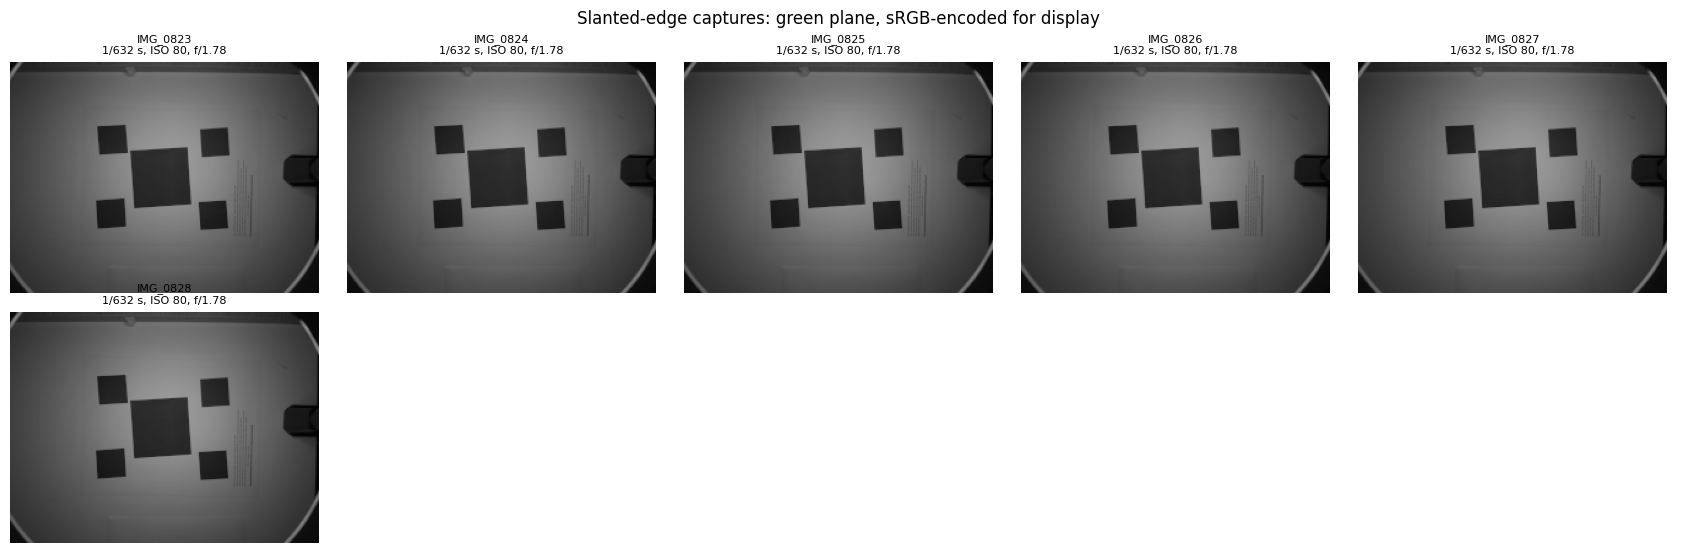

file,exposure_s,ISO,N,f_mm
IMG_0823.DNG,0.001582,80,1.780000,6.765000
IMG_0824.DNG,0.001582,80,1.780000,6.765000
IMG_0825.DNG,0.001582,80,1.780000,6.765000
IMG_0826.DNG,0.001582,80,1.780000,6.765000
IMG_0827.DNG,0.001582,80,1.780000,6.765000
IMG_0828.DNG,0.001582,80,1.780000,6.765000


In [19]:
EDGE_FILES = dng_files(EDGE_DIR)


def green_plane(path):
    """Return (green plane in DN, black level of that plane, white level, (row, col) of the site).
    Takes the first green site of the 2x2 Bayer tile, so it is one green channel, not a mix of G1 and G2."""
    with rawpy.imread(str(path)) as r:
        if r.raw_pattern is None or r.raw_image_visible.ndim != 2:
            raise ValueError(f"{Path(path).name} is not a Bayer mosaic (ProRAW / LinearRaw?). "
                             "Use the same raw app and settings as the Exercise 1 captures.")
        raw = r.raw_image_visible.astype(np.float64)     # copy before the file closes
        pattern = r.raw_pattern.copy()
        desc = r.color_desc.decode()
        gi, gj = next((i, j) for i in range(2) for j in range(2) if desc[pattern[i, j]] == "G")
        black = float(r.black_level_per_channel[pattern[gi, gj]])
        white = float(r.white_level)
        row_mate = desc[pattern[gi, 1 - gj]]               # the other colour on the same rows
    return raw[gi::2, gj::2], black, white, (gi, gj, row_mate)


def thumbnail(plane, black, white, factor=8):
    """Normalize to [0, 1] of the raw range, block-average in linear light, then sRGB-encode for display."""
    x = (plane - black) / (white - black)
    h, w = (s // factor * factor for s in x.shape)
    x = x[:h, :w].reshape(h // factor, factor, w // factor, factor).mean(axis=(1, 3))
    return srgb_encode(x)


if not EDGE_FILES:
    print(f"No captures yet in '{EDGE_DIR}'. Put at least five Bayer raw DNGs of the slanted-edge "
          "target there and re-run from this cell.")
else:
    edge_exif = pd.DataFrame([camera_exif(f) for f in EDGE_FILES])
    print(f"{len(EDGE_FILES)} captures in '{EDGE_DIR}'" +
          ("" if len(EDGE_FILES) >= 5 else "   ! the assignment asks for at least five"))
    ncols = min(5, len(EDGE_FILES))
    nrows = int(np.ceil(len(EDGE_FILES) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 2.8 * nrows), squeeze=False)
    for ax, f, row in zip(axes.flat, EDGE_FILES, edge_exif.itertuples()):
        g, black, white, _ = green_plane(f)
        ax.imshow(thumbnail(g, black, white), cmap="gray", vmin=0, vmax=1)
        exp = f"1/{1 / row.exposure_s:.0f} s" if row.exposure_s < 1 else f"{row.exposure_s:g} s"
        ax.set_title(f"{f.stem}\n{exp}, ISO {row.ISO}, f/{row.N:.2f}", fontsize=8)
        ax.axis("off")
    for ax in axes.flat[len(EDGE_FILES):]:
        ax.axis("off")
    fig.suptitle("Slanted-edge captures: green plane, sRGB-encoded for display")
    fig.tight_layout()
    plt.show()
    display(edge_exif[["file", "exposure_s", "ISO", "N", "f_mm"]].style.hide(axis="index"))

### Problem 13: Confirm with the lens_id assertion from the Project 1 page that every capture came from the same camera.
_Deliverable: The assertion passing, or an account of which captures came from a different camera._

In [20]:
if not EDGE_FILES:
    print("No captures yet.")
else:
    ids = pd.DataFrame([{"file": f.name, "lens_id": lens_id(f)} for f in EDGE_FILES])
    print(ids.to_string(index=False))
    distinct = set(ids.lens_id)
    assert len(distinct) == 1, f"Captures came from {len(distinct)} cameras: {distinct}"
    print(f"\nAssertion passed: all {len(ids)} captures came from {next(iter(distinct))}")

    # Not required, but Part 2 rests on these: same camera as the calibration, same f-number
    cal_id = lens_id(CAL_DIR / used_names[0])
    print(f"Same camera as the calibration captures: {next(iter(distinct)) == cal_id}")
    print(f"f-number in these captures: {sorted(edge_exif.N.round(3).unique())}; prediction used f/{N:.3f}")

        file                                                                 lens_id
IMG_0823.DNG (iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765, 24, (4032, 3024))
IMG_0824.DNG (iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765, 24, (4032, 3024))
IMG_0825.DNG (iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765, 24, (4032, 3024))
IMG_0826.DNG (iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765, 24, (4032, 3024))
IMG_0827.DNG (iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765, 24, (4032, 3024))
IMG_0828.DNG (iPhone 16 Pro Max back camera 6.765mm f/1.78, 6.765, 24, (4032, 3024))

Assertion passed: all 6 captures came from ('iPhone 16 Pro Max back camera 6.765mm f/1.78', 6.765, 24, (4032, 3024))
Same camera as the calibration captures: True
f-number in these captures: [np.float64(1.78)]; prediction used f/1.780


### Problem 14: Extract one green plane from the Bayer mosaic of each capture and subtract the black level, so that the data are linear in scene radiance.
_Deliverable: One extracted green plane displayed, and a statement of which green plane and which black level you used._

Green plane: Bayer site (row 0, column 1) of each 2x2 tile, the green on the B rows; shape (1512, 2016), spacing 2p = 4.843 µm
Black level subtracted: 528 DN (from black_level_per_channel for that site); white level 4095 DN


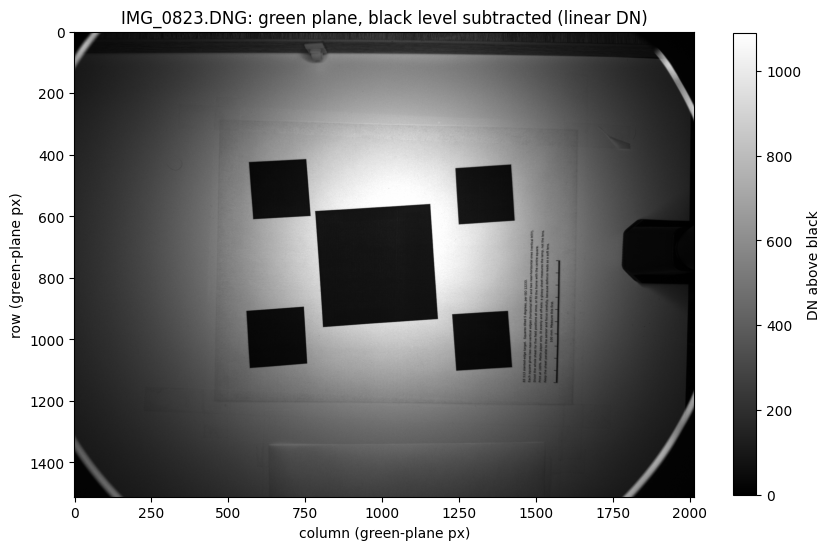

In [21]:
if not EDGE_FILES:
    print("No captures yet.")
else:
    planes = {}
    for f in EDGE_FILES:
        g, black, white, site = green_plane(f)
        planes[f.name] = {"linear": g - black, "black": black, "full_scale": white - black, "site": site}

    first = planes[EDGE_FILES[0].name]
    gi, gj, mate = first["site"]
    print(f"Green plane: Bayer site (row {gi}, column {gj}) of each 2x2 tile, the green on the "
          f"{mate} rows; shape {first['linear'].shape}, spacing 2p = {2 * p_um:.3f} µm")
    print(f"Black level subtracted: {first['black']:.0f} DN (from black_level_per_channel for that site); "
          f"white level {first['black'] + first['full_scale']:.0f} DN")
    blacks = {v["black"] for v in planes.values()}
    if len(blacks) > 1:
        print("! Black level differs between captures:", blacks)

    lin = first["linear"]
    fig, ax = plt.subplots(figsize=(10, 7.5))
    im = ax.imshow(lin, cmap="gray", vmin=0, vmax=np.percentile(lin, 99.5))
    ax.set_title(f"{EDGE_FILES[0].name}: green plane, black level subtracted (linear DN)")
    ax.set_xlabel("column (green-plane px)"); ax.set_ylabel("row (green-plane px)")
    fig.colorbar(im, ax=ax, shrink=0.8, label="DN above black")
    plt.show()

### **Which green plane and black level did I use?**
I used the green site at row 0, column 1 of each 2×2 Bayer tile (the green on the blue rows of the BGGR mosaic, a 1512 × 2016 plane sampled every 2p = 4.843 µm) and subtracted the black level of 528 DN that the DNG records for that site in black_level_per_channel.

### Problem 15: Measure MTF50 on the central square of the target in each of your captures, and report the mean and standard deviation across them.
_Deliverable: MTF50 as mean ± standard deviation, in cycles per micrometer and in cycles per green-plane pixel._

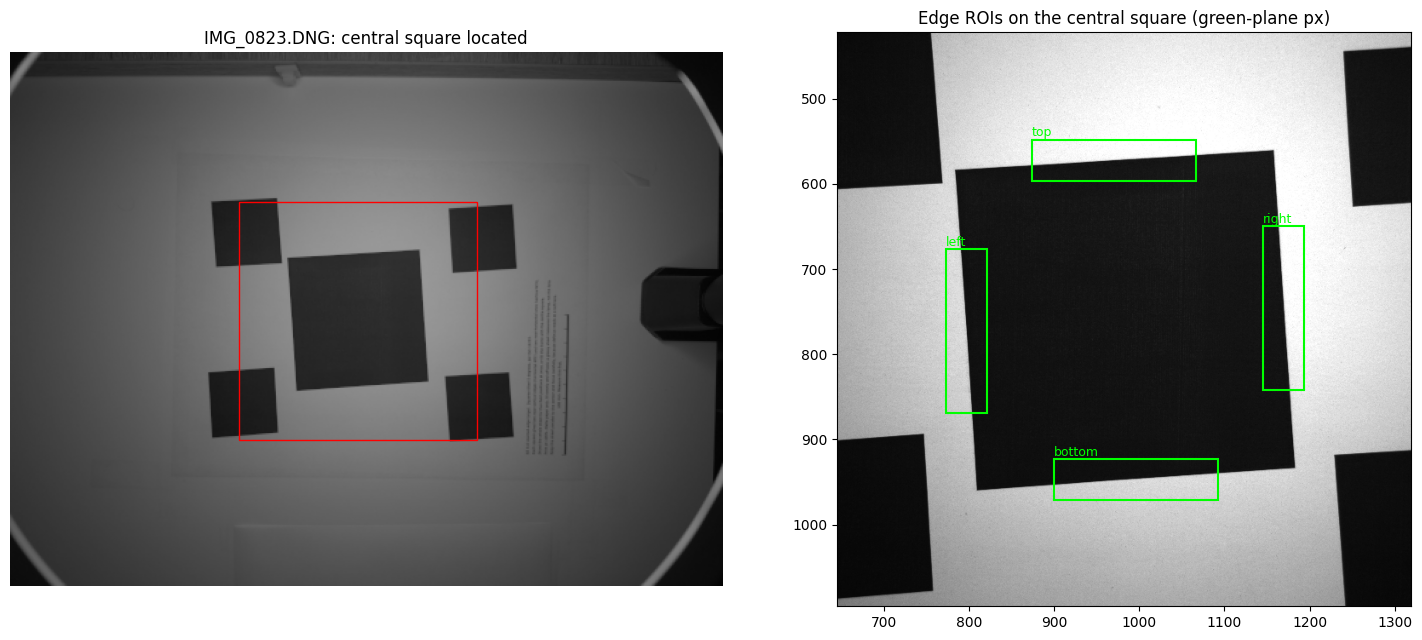

Measured edge angles: 3.49° to 3.96° from the pixel axes


In [22]:
EDGE_HALF_WIDTH = 24        # green-plane px either side of the edge in each ROI
EDGES_TO_USE = ("left", "right", "top", "bottom")   # edges of the central square to average
MANUAL_CENTER = None        # (x, y) of the central square in green-plane px, if detection picks the wrong one
F_NYQ_GP = 0.5              # green-plane Nyquist, cycles per green-plane pixel


def find_squares(lin, reduce=4):
    """Dark, roughly square blobs in the green plane, with their rotated bounding boxes (x, y in green px)."""
    h, w = lin.shape
    small = cv2.resize(lin, (w // reduce, h // reduce), interpolation=cv2.INTER_AREA)
    lo, hi = np.percentile(small, [1, 99])
    u8 = np.clip(255 * (small - lo) / (hi - lo), 0, 255).astype(np.uint8)
    _, bw = cv2.threshold(cv2.GaussianBlur(u8, (5, 5), 0), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(bw, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
    out = []
    for c in contours:
        area = cv2.contourArea(c)
        if not (2e-4 * small.size < area < 0.25 * small.size):
            continue
        rect = cv2.minAreaRect(c)
        (rw, rh) = rect[1]
        if min(rw, rh) / max(rw, rh) < 0.8 or area / (rw * rh) < 0.85:
            continue
        box = cv2.boxPoints(rect) * reduce + (reduce - 1) / 2
        out.append({"center": np.array(rect[0]) * reduce + (reduce - 1) / 2, "box": box,
                    "side": 0.5 * (rw + rh) * reduce})
    return out


def central_square(lin):
    squares = find_squares(lin)
    if not squares:
        raise RuntimeError("No square found; set MANUAL_CENTER or check the exposure.")
    target = np.array(MANUAL_CENTER if MANUAL_CENTER else (lin.shape[1] / 2, lin.shape[0] / 2))
    return min(squares, key=lambda s: np.hypot(*(s["center"] - target)))


def edge_rois(square, shape):
    """One ROI per side of the square: (name, row0, row1, col0, col1). Each straddles the edge,
    stays inside the square on one side, and is short enough along the edge that the 5° tilt
    keeps the edge well inside the ROI."""
    box, ctr = square["box"], square["center"]
    rois = []
    for a, b in zip(box, np.roll(box, -1, axis=0)):
        mid, v = (a + b) / 2, b - a
        L = np.hypot(*v)
        hw = int(min(EDGE_HALF_WIDTH, 0.3 * L))
        along = int(min(0.3 * L, 4 * hw))
        vertical = abs(v[1]) > abs(v[0])
        if vertical:
            name = "left" if mid[0] < ctr[0] else "right"
            r0, r1, c0, c1 = mid[1] - along, mid[1] + along, mid[0] - hw, mid[0] + hw
        else:
            name = "top" if mid[1] < ctr[1] else "bottom"
            r0, r1, c0, c1 = mid[1] - hw, mid[1] + hw, mid[0] - along, mid[0] + along
        r0, c0 = max(int(round(r0)), 0), max(int(round(c0)), 0)
        r1, c1 = min(int(round(r1)), shape[0]), min(int(round(c1)), shape[1])
        rois.append((name, r0, r1, c0, c1))
    return sorted(rois, key=lambda r: ("left", "right", "top", "bottom").index(r[0]))


def measure_plane(lin, full_scale):
    """MTF of each edge of the central square in one black-subtracted green plane."""
    sq = central_square(lin)
    rows, results = [], {}
    for name, r0, r1, c0, c1 in edge_rois(sq, lin.shape):
        roi = lin[r0:r1, c0:c1]
        res = slanted_edge_mtf(roi, f_max=1.5)
        results[name] = res
        rows.append({"edge": name, "roi": (r0, r1, c0, c1),
                     "angle_deg": res["angle_deg"],
                     "mtf50_cyc_per_gpx": res["mtf50"],
                     "mtf_at_nyquist": mtf_at(res, F_NYQ_GP),
                     "pct_clipped": 100 * np.mean(roi >= 0.98 * full_scale),
                     "dark_DN": np.percentile(roi, 5), "light_DN": np.percentile(roi, 95)})
    return sq, pd.DataFrame(rows), results


if not EDGE_FILES:
    print("No captures yet.")
else:
    per_edge, curves, squares_found = [], {}, {}
    for f in EDGE_FILES:
        pl = planes[f.name]
        sq, df, res = measure_plane(pl["linear"], pl["full_scale"])
        df.insert(0, "file", f.name)
        per_edge.append(df)
        curves[f.name] = res
        squares_found[f.name] = sq
    per_edge = pd.concat(per_edge, ignore_index=True)

    # ROIs on the first capture, so the detection can be checked by eye
    name0 = EDGE_FILES[0].name
    lin, sq = planes[name0]["linear"], squares_found[name0]
    pad = int(0.9 * sq["side"])
    cxg, cyg = sq["center"].astype(int)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
    axes[0].imshow(thumbnail(lin, 0, planes[name0]["full_scale"], 4), cmap="gray", vmin=0, vmax=1)
    axes[0].add_patch(Rectangle(((cxg - pad) / 4, (cyg - pad) / 4), 2 * pad / 4, 2 * pad / 4,
                                fill=False, edgecolor="red"))
    axes[0].set_title(f"{name0}: central square located"); axes[0].axis("off")
    axes[1].imshow(lin, cmap="gray", vmin=0, vmax=np.percentile(lin, 99.5))
    for row in per_edge[per_edge.file == name0].itertuples():
        r0, r1, c0, c1 = row.roi
        used = row.edge in EDGES_TO_USE
        axes[1].add_patch(Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, lw=1.5,
                                    edgecolor="lime" if used else "gray"))
        axes[1].text(c0, r0 - 4, row.edge, color="lime" if used else "gray", fontsize=9)
    axes[1].set_xlim(cxg - pad, cxg + pad); axes[1].set_ylim(cyg + pad, cyg - pad)
    axes[1].set_title("Edge ROIs on the central square (green-plane px)")
    fig.tight_layout()
    plt.show()

    if per_edge.pct_clipped.max() > 0:
        print(f"! Clipped pixels in an ROI (max {per_edge.pct_clipped.max():.2f}%): reduce the exposure.")
    angles = per_edge.angle_deg.abs()
    print(f"Measured edge angles: {angles.min():.2f}° to {angles.max():.2f}° from the pixel axes")

Central square, edges left, right, top, bottom, averaged per capture; mean ± standard deviation across 6 captures:
  MTF50 = 0.403 ± 0.032 cycles per green-plane pixel
        = 0.0833 ± 0.0066 cycles/µm  (83.3 ± 6.6 cycles/mm)

By edge (cycles per green-plane pixel; left/right = horizontal frequency, top/bottom = vertical):
         mean    std
edge                
left    0.484  0.034
right   0.370  0.033
top     0.366  0.030
bottom  0.393  0.033


,mtf50_cyc_per_gpx,mtf_at_nyquist,mtf50_cyc_per_um
file,,,
IMG_0823.DNG,0.4196,0.4251,0.0866
IMG_0824.DNG,0.3897,0.3871,0.0805
IMG_0825.DNG,0.4227,0.4234,0.0873
IMG_0826.DNG,0.4403,0.4401,0.0909
IMG_0827.DNG,0.3998,0.3968,0.0826
IMG_0828.DNG,0.3487,0.3534,0.0720


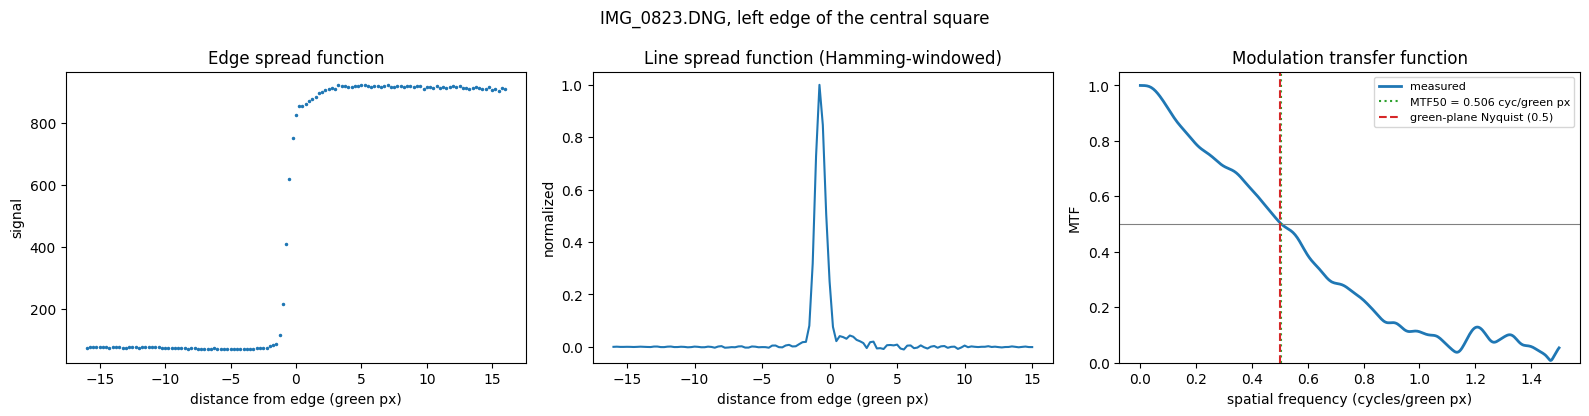

In [23]:
if EDGE_FILES:
    used = per_edge[per_edge.edge.isin(EDGES_TO_USE)]
    per_capture = used.groupby("file").agg(mtf50_cyc_per_gpx=("mtf50_cyc_per_gpx", "mean"),
                                           mtf_at_nyquist=("mtf_at_nyquist", "mean"))
    per_capture["mtf50_cyc_per_um"] = per_capture.mtf50_cyc_per_gpx / (2 * p_um)

    m_gp, s_gp = per_capture.mtf50_cyc_per_gpx.mean(), per_capture.mtf50_cyc_per_gpx.std(ddof=1)
    m_um, s_um = m_gp / (2 * p_um), s_gp / (2 * p_um)
    print(f"Central square, edges {', '.join(EDGES_TO_USE)}, averaged per capture; "
          f"mean ± standard deviation across {len(per_capture)} captures:")
    print(f"  MTF50 = {m_gp:.3f} ± {s_gp:.3f} cycles per green-plane pixel")
    print(f"        = {m_um:.4f} ± {s_um:.4f} cycles/µm  ({1000 * m_um:.1f} ± {1000 * s_um:.1f} cycles/mm)")

    by_edge = (per_edge.groupby("edge").mtf50_cyc_per_gpx.agg(["mean", "std"])
               .reindex(["left", "right", "top", "bottom"]))
    print("\nBy edge (cycles per green-plane pixel; left/right = horizontal frequency, top/bottom = vertical):")
    print(by_edge.round(3).to_string())
    display(per_capture.round(4))

    # ESF / LSF / MTF for one edge of the first capture
    e0 = EDGES_TO_USE[0]
    plot_sfr(curves[EDGE_FILES[0].name][e0], f"{EDGE_FILES[0].name}, {e0} edge of the central square",
             unit="green px", f_mark=F_NYQ_GP, f_mark_label="green-plane Nyquist (0.5)")

### Problem 16: Compare your measurement against your prediction by reporting the predicted modulation at the Nyquist frequency from item 7 alongside the measured value at the same frequency. The prediction accounted for diffraction and the photodiode aperture only. Identify the effects present in the real system that it omitted, state which one you believe dominates, and describe a measurement that would distinguish between them.
_Deliverable: Predicted and measured modulation at Nyquist, and a written analysis (4–5 sentences)._

At the green-plane Nyquist frequency 0.1032 cycles/µm (0.5 cycles per green-plane pixel):
  predicted modulation (item 7, frozen 2026-11-11T23:04:20): 0.785
  measured modulation: 0.404 ± 0.032
MTF50 predicted 0.1980 cycles/µm, measured 0.0833 ± 0.0066 cycles/µm


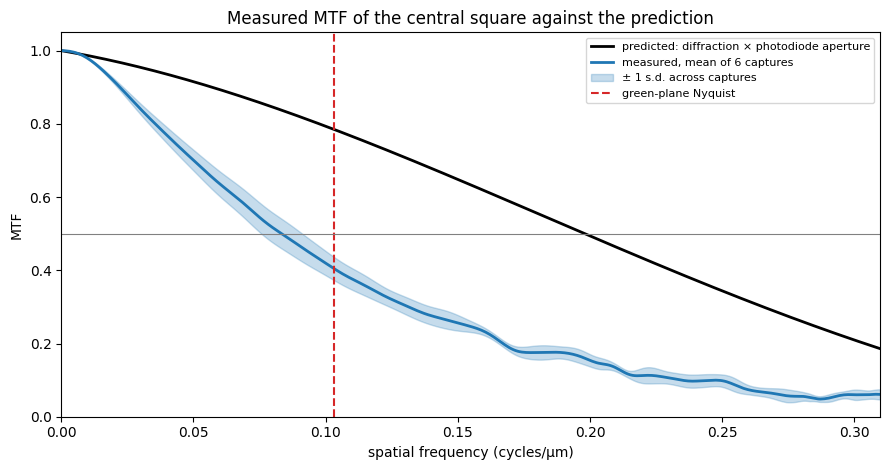

In [24]:
if not EDGE_FILES:
    print("No captures yet.")
else:
    frozen = json.loads(PREDICTION_FILE.read_text())
    m_nyq, s_nyq = per_capture.mtf_at_nyquist.mean(), per_capture.mtf_at_nyquist.std(ddof=1)
    print(f"At the green-plane Nyquist frequency {frozen['nyquist_green_cyc_per_um']:.4f} cycles/µm "
          f"(0.5 cycles per green-plane pixel):")
    print(f"  predicted modulation (item 7, frozen {frozen['written']}): {frozen['mtf_at_green_nyquist']:.3f}")
    print(f"  measured modulation: {m_nyq:.3f} ± {s_nyq:.3f}")
    print(f"MTF50 predicted {frozen['mtf50_cyc_per_um']:.4f} cycles/µm, measured {m_um:.4f} ± {s_um:.4f} cycles/µm")

    # Measured curves against the prediction, on one axis in cycles/µm
    f_gp = next(iter(curves.values()))[EDGES_TO_USE[0]]["freq"]
    stack = np.array([[np.interp(f_gp, r["freq"], r["mtf"]) for e, r in res.items() if e in EDGES_TO_USE]
                      for res in curves.values()]).mean(axis=1)          # per capture, edges averaged
    nu_meas = f_gp / (2 * p_um)
    fig, ax = plt.subplots(figsize=(9, 4.8))
    ax.plot(nu, mtf_predicted(nu), "k", lw=2, label="predicted: diffraction × photodiode aperture")
    ax.plot(nu_meas, stack.mean(axis=0), color="tab:blue", lw=2, label=f"measured, mean of {len(stack)} captures")
    ax.fill_between(nu_meas, stack.mean(axis=0) - stack.std(axis=0, ddof=1),
                    stack.mean(axis=0) + stack.std(axis=0, ddof=1), color="tab:blue", alpha=0.25,
                    label="± 1 s.d. across captures")
    ax.axvline(frozen["nyquist_green_cyc_per_um"], color="tab:red", ls="--", label="green-plane Nyquist")
    ax.axhline(0.5, color="gray", lw=0.8)
    ax.set_xlim(0, nu_meas.max()); ax.set_ylim(0, 1.05)
    ax.set_xlabel("spatial frequency (cycles/µm)"); ax.set_ylabel("MTF")
    ax.set_title("Measured MTF of the central square against the prediction")
    ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

### **How does the measurement compare with the prediction?**
**At the green-plane Nyquist frequency (0.1032 cycles/µm):** the prediction was 0.785 and I measured 0.404 ± 0.032. The measured MTF50 is 0.0833 ± 0.0066 cycles/µm against 0.1980 cycles/µm predicted, so the camera keeps about half the predicted contrast at Nyquist and falls to 50 % at less than half the predicted frequency.

**Effects the prediction omitted:**
* **Lens aberrations** (spherical aberration, coma, astigmatism and field curvature): a phone lens at f/1.78 is far from diffraction-limited.
* **Defocus:** autofocus is never exact, and the depth of field at f/1.78 is shallow.
* **Sensor effects beyond an ideal photodiode:** optical and electrical crosstalk between neighbouring pixels, and the 2×2 binning of the quad-pixel sensor.
* **The target itself:** a laser-printed edge is not a perfect step.

**Which one dominates:** I believe lens aberrations dominate. Diffraction and the pixel aperture are the same everywhere in the frame, and the print and crosstalk would blur every edge equally, yet MTF50 measured the same way on the corner squares of these captures falls from 0.40 on the central square to 0.26–0.32 on the corner squares, only a quarter to two-fifths of the way to the frame corner, which is the signature of off-axis aberrations such as astigmatism and field curvature. Defocus is a smaller but real second effect: all four edges rise and fall together from one capture to the next (the 8 % spread), which a focus shift produces but photon noise does not.

_The corner-square values come from a separate check that ran this notebook's `slanted_edge_mtf` on all four edges of each of the four corner squares in the same six captures (IMG_0823 to IMG_0828); the notebook itself reports only the central square._

**A measurement that would distinguish them:** A through-focus series would separate the two: photograph the target at a series of manually stepped focus positions and plot MTF50 against focus at the centre and at each corner. Defocus is the part that changes with focus, so each curve's peak shows how much sharpness perfect focus would recover, the height of that peak is the limit set by aberrations, and a best-focus position that differs between the centre and the corners would confirm field curvature.

## Part 5: Reflections
### Problem 17: What did you learn from this assignment?
_Deliverable: A brief written response._

**Part 1: Camera Geometry**
* Pixel pitch two ways (calibration against EXIF)
* Quad-pixel binning on iPhone 16 Pro Max: the 12 MP raw file has a 2.44 µm effective pixel

**Part 2: Predicted Response**
* MTF as a chain: the stages multiply (diffraction × pixel aperture)

**Part 3: Validating the Measurement**
* The slanted-edge method: edge profile → line spread → MTF
* The method’s own blur (binning, finite differences, window width) and correcting for it

**Part 4: Measurement**
* Sharpness falling off away from the centre of the frame (field-dependent lens blur)
* Predicted against measured: why a phone lens falls well short of the diffraction-plus-pixel prediction (aberrations, defocus)
* Iterating on the setup: four slanted-edge photo sessions, each one showing a different problem

**General:**
* Using AI tools to check and compare outputs independently

### Problem 18: What questions, if any, do you have for me after completing this assignment?
_Deliverable: A brief written response._

I have no questions at this time.